# NB18: Scientific Module Gallery

**Purpose**: Survey all 7 scientific domains in RELIC, demonstrating one
representative Functor from each domain.

This is the RELIC equivalent of WRF's "Physics Module" lecture series,
where each physical parameterization is explained and demonstrated.

## The Seven Domains

| Domain | RELIC Module | WRF/CMAQ Analog |
|---|---|---|
| Atmosphere | `relic.scientific.atmosphere` | WRF: mp, ra, sf, cu |
| Biosphere | `relic.scientific.biosphere` | CLM/NOAH-MP |
| Hydrosphere | `relic.scientific.hydrosphere` | VIC/NOAHMP |
| Pedosphere | `relic.scientific.pedosphere` | Century/RothC |
| Anthroposphere | `relic.scientific.anthroposphere` | CMAQ: emissions |
| Transport | `relic.scientific.transport` | WRF: advection |
| Isotopes | `relic.scientific.isotopes` | (no analog) |

**Time**: ~8 minutes


## Architecture Anchor

This notebook follows `docs\source\architecture_overview.md`. It surveys actual RELIC classes and calls selected numerical utilities and Functor kernels directly. These calls do not establish a governed simulator run, StateManager transaction, complete coupled budget, or strict IPHS certification. The Langmuir panel is explicitly an illustrative formula, and the isotope runtime remains unavailable.


## Domain 1: Atmosphere -- Radiation & Turbulence

The atmosphere domain handles energy inputs to the ecosystem:
shortwave/longwave radiation, turbulent exchange, and atmospheric chemistry.


In [1]:
# Use only the standard library so notebook execution stays self-contained on Windows.
import asyncio
if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

# ---------------------------------------------------------------
# References: Campbell and Norman (1998); RadiationField.forward.
# Mathematical expression: R_out = clamp(R_state, R_min, R_max).
# Parameter meanings: R_state is the supplied grid field; bounds come from ParameterManager.
# Units: coordinates [m], field [W m-2], gradients [W m-3].
# Domain/constraints: finite tensors on the explicit two-dimensional field grid.
# Sign convention: positive field values are radiation magnitudes; this is a field diagnostic.
# ---------------------------------------------------------------

import os; os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import sys
PROJECT_ROOT = os.environ.get('RELIC_PROJECT_ROOT', os.getcwd())
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import torch

# REAL RELIC functor: RadiationField
from relic.scientific.atmosphere.radiation import RadiationField

rad = RadiationField(device=torch.device('cpu'))

grid_coordinates = torch.tensor([
    [0.0, 0.0],
    [100.0, 0.0],
    [0.0, 100.0],
    [100.0, 100.0],
], dtype=torch.float32)
initial_radiation = torch.tensor([420.0, 405.0, 390.0, 375.0], dtype=torch.float32)
rad.initialize_field(grid_coordinates, initial_values=initial_radiation)

print("=== Domain 1: Atmosphere -- RadiationField ===")
print(f"  Class:     {type(rad).__name__}")
print(f"  Module:    relic.scientific.atmosphere.radiation")
print(f"  Category:  {rad.metadata.category}")
print(f"  Inputs:    {rad.metadata.input_variables}")
print(f"  Outputs:   {rad.metadata.output_variables}")
print()

# Demo forward pass on an explicit RELIC field grid.
state_rad = {'grid_coordinates': grid_coordinates, 'radiation_field': initial_radiation}
out_rad = rad.forward(state_rad, time=0.0, dt=1800.0, return_gradients=True)
radiation_field = out_rad['radiation_field'].value
print(f"  Grid points: {grid_coordinates.shape[0]}")
print(f"  Forward output keys: {list(out_rad.keys())[:5]}")
print(
    f"  Radiation range: {radiation_field.min().detach().item():.2f} "
    f"to {radiation_field.max().detach().item():.2f} W/m2"
)
if 'diagnostics.radiation_field.gradient' in out_rad:
    gradient = out_rad['diagnostics.radiation_field.gradient'].value
    print(f"  Gradient shape: {tuple(gradient.shape)}")
print("[OK] RadiationField initialized on an explicit RELIC grid and forward pass successful")

=== Domain 1: Atmosphere -- RadiationField ===
  Class:     RadiationField
  Module:    relic.scientific.atmosphere.radiation
  Category:  ProcessCategory.PHYSICAL_FIELD
  Inputs:    ['grid_coordinates', 'radiation_field', 'source_coordinates']
  Outputs:   ['radiation_field', 'diagnostics.radiation_field.gradient', 'diagnostics.radiation_field.clipping_residual', 'diagnostics.radiation_field.query_clipping_residual']

  Grid points: 4
  Forward output keys: ['radiation_field', 'diagnostics.radiation_field.gradient']
  Radiation range: 375.00 to 420.00 W/m2
  Gradient shape: (4, 2)
[OK] RadiationField initialized on an explicit RELIC grid and forward pass successful


## Domain 2: Biosphere -- Photosynthesis & Growth

The biosphere domain includes the Farquhar model for
C3/C4 photosynthesis, autotrophic respiration, phenology, BVOC emissions, and growth.


In [2]:
# ---------------------------------------------------------------
# References:
#   Farquhar et al. (1980), Planta -- C3 photosynthesis model
#   Ball et al. (1987) -- Ball-Berry stomatal conductance
#   Collatz et al. (1991) -- C4 photosynthesis
# Mathematical expression:
#   A = min(Ac, Aj, Ap) - Rd
#   Ac = Vcmax * (Ci - Gamma*) / (Ci + Kc*(1 + O/Ko))
#   Aj = J * (Ci - Gamma*) / (4*Ci + 8*Gamma*)
# Parameter meanings:
#   Vcmax: maximum carboxylation rate [umol/m2/s]
#   Jmax: maximum electron transport rate [umol e- m-2 s-1]
#   Rd: dark respiration [umol/m2/s]
# Units: biochemical rates [umol CO2 m-2 s-1]; exported GPP [kg C m-2 s-1].
# Domain/constraints: canonical forcing tensors are finite; stress factors lie in [0, 1].
# Sign convention: gross_primary_productivity is positive carbon uptake into vegetation.
# ---------------------------------------------------------------

# REAL RELIC functor: FarquharPhotosynthesis
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis

photo = FarquharPhotosynthesis(
    name='farquhar_photosynthesis',
    vcmax25=60.0,
    jmax25=120.0,
    rd25=1.5,
    device=torch.device('cpu'),
)

print("=== Domain 2: Biosphere -- FarquharPhotosynthesis ===")
print(f"  Class:     {type(photo).__name__}")
print(f"  Module:    relic.scientific.biosphere.photosynthesis.farquhar")
print(f"  Category:  {photo.metadata.category}")
print(f"  Inputs:    {photo.metadata.input_variables}")
print(f"  Outputs:   {photo.metadata.output_variables}")
print()

# Demo forward pass
state_photo = {
    'air_temperature': torch.tensor(298.15),
    'atmospheric_co2_ppm': torch.tensor(400.0),
    'ppfd': torch.tensor(1500.0),
    'vcmax_scaling': torch.tensor(1.0),
    'jmax_scaling': torch.tensor(1.0),
    'water_stress_factor': torch.tensor(1.0),
    'temperature_stress_factor': torch.tensor(1.0),
    'ozone_stress_factor': torch.tensor(1.0),
    'vapor_pressure_deficit': torch.tensor(1000.0),
    'leaf_area_index': torch.tensor(5.0),
}
out_photo = photo.forward(state_photo, time=0.0, dt=1800.0)
print(f"  Forward output keys: {list(out_photo.keys())[:6]}")
gpp_value = out_photo['gross_primary_productivity'].value.detach().item()
print(f"  GPP: {gpp_value:.6e} kg C m-2 s-1")
print("[OK] FarquharPhotosynthesis forward pass successful")

=== Domain 2: Biosphere -- FarquharPhotosynthesis ===
  Class:     FarquharPhotosynthesis
  Module:    relic.scientific.biosphere.photosynthesis.farquhar
  Category:  ProcessCategory.BIOLOGICAL_PROCESS
  Inputs:    ['air_temperature', 'atmospheric_co2_ppm', 'ppfd', 'vapor_pressure_deficit', 'vcmax_scaling', 'vpmax_scaling', 'jmax_scaling', 'water_stress_factor', 'temperature_stress_factor', 'ozone_stress_factor', 'leaf_area_index']
  Outputs:   ['gross_photosynthesis', 'net_photosynthesis', 'gross_primary_productivity', 'electron_transport_rate', 'diagnostics.photosynthesis.dark_respiration', 'diagnostics.photosynthesis.transport_limited', 'diagnostics.photosynthesis.jmax_actual', 'diagnostics.photosynthesis.limitation_factor', 'diagnostics.photosynthesis.pathway_type']

  Forward output keys: ['gross_photosynthesis', 'net_photosynthesis', 'gross_primary_productivity', 'electron_transport_rate', 'diagnostics.photosynthesis.dark_respiration', 'diagnostics.photosynthesis.transport_limite

## Domain 3: Hydrosphere -- Soil Moisture & ET

The hydrosphere handles water movement through the soil-plant-atmosphere continuum.


In [3]:
# ---------------------------------------------------------------
# References:
#   Clapp & Hornberger (1978) -- soil hydraulic parameters
#   Penman-Monteith (1965) -- evapotranspiration
#   Richards (1931) -- vadose zone flow equation
# Mathematical expression:
#   theta(t+dt) = theta(t) + (P - ET - D) * dt / dz
#   K(theta) = K_sat * (theta/theta_s)^(2b+3)
# Parameter meanings:
#   theta: volumetric soil moisture [m3/m3]
#   K_sat: saturated hydraulic conductivity [m/s]
#   b: Clapp-Hornberger exponent [-]
# ---------------------------------------------------------------

# REAL RELIC functor: BucketSoilMoisture
from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture
sm = BucketSoilMoisture(
    name='bucket_soil_moisture',
)
print("=== Domain 3: Hydrosphere -- BucketSoilMoisture ===")
print(f"  Class:     {type(sm).__name__}")
print(f"  Module:    relic.scientific.hydrosphere.soil_moisture.bucket")
print(f"  Category:  {sm.metadata.category}")
print(f"  Inputs:    {sm.metadata.input_variables}")
print(f"  Outputs:   {sm.metadata.output_variables}")
print("[OK] BucketSoilMoisture instantiated")

=== Domain 3: Hydrosphere -- BucketSoilMoisture ===
  Class:     BucketSoilMoisture
  Module:    relic.scientific.hydrosphere.soil_moisture.bucket
  Category:  ProcessCategory.TRANSPORT_MECHANISM
  Inputs:    ['soil_moisture', 'precipitation_flux', 'evapotranspiration_flux']
  Outputs:   ['soil_moisture', 'surface_runoff_flux', 'drainage_flux', 'diagnostics.soil_moisture_bucket']
[OK] BucketSoilMoisture instantiated


### H1. Soil Hydraulic Utilities and Groundwater Diagnostics

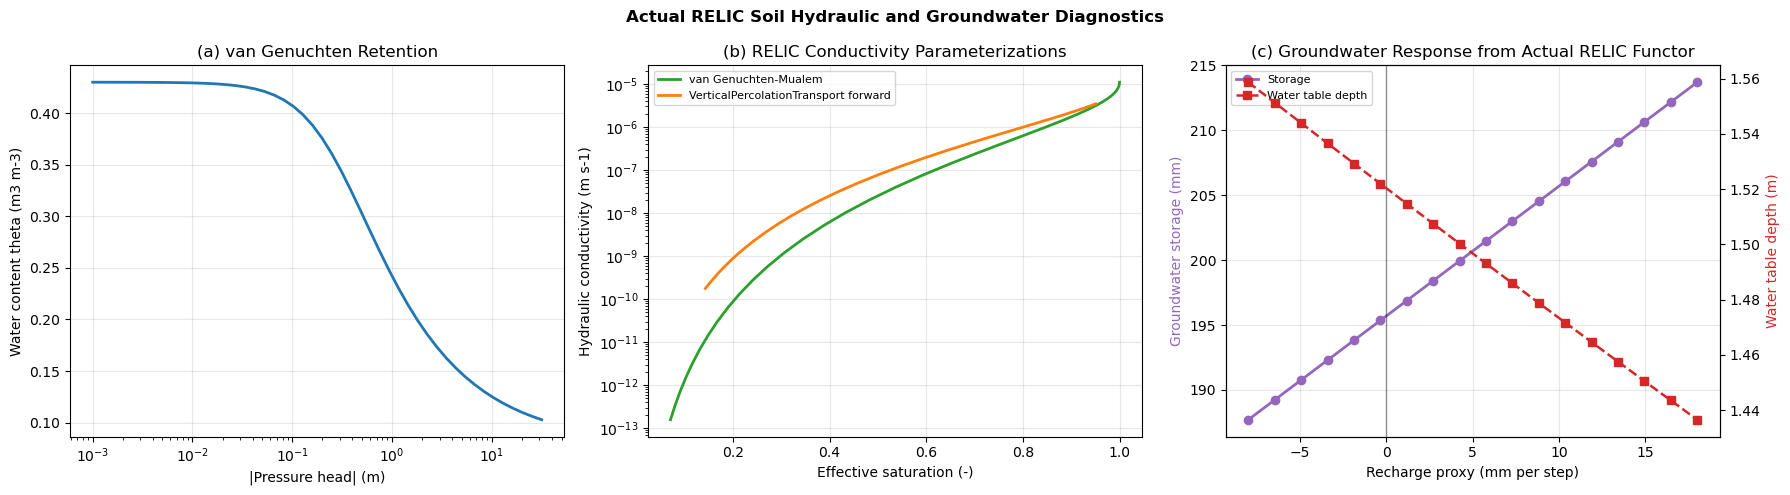

  theta range: 0.1028 to 0.4300 m3 m-3
  van Genuchten conductivity range: 1.575e-13 to 1.099e-05 m s-1
  Transport conductivity range: 1.777e-10 to 3.462e-06 m s-1
  Groundwater storage response: 187.70 to 213.70 mm
  Water table depth response: 1.437 to 1.559 m
  Pressure-head roundtrip max abs error: 1.526e-05 m


In [4]:
# Uses actual RELIC hydraulic utility functions and groundwater diagnostics rather than notebook-defined curves.
from relic.utils.soil_hydraulics import (
    effective_saturation,
    van_genuchten_mualem_conductivity,
    van_genuchten_pressure_head,
    van_genuchten_water_retention,
)
from relic.scientific.hydrosphere.groundwater.dynamics import GroundwaterDynamics
from relic.scientific.hydrosphere.transport.vertical_percolation import VerticalPercolationTransport
from relic.core.state import UpdateItem
from relic.utils.physical_constants import get_physical_constant

# ---------------------------------------------------------------
# References:
#   van Genuchten (1980) -- water retention curve
#   Mualem (1976) -- unsaturated conductivity closure
#   RHESSys groundwater storage diagnostics used in GroundwaterDynamics
# Mathematical expression:
#   theta(h) = theta_r + (theta_s - theta_r) / (1 + (alpha * |h|)^n)^m
#   Se = (theta - theta_r) / (theta_s - theta_r)
#   K(Se) = Ks * Se^l * [1 - (1 - Se^(1/m))^m]^2
#   n(z) = n0 * exp(-z / p)
# Parameter meanings:
#   pressure_head: matric pressure head [m]
#   theta_r, theta_s: residual and saturated water content [m3 m-3]
#   alpha_vg, n_vg: van Genuchten shape parameters
#   Ks: saturated hydraulic conductivity [m s-1]
#   recharge_proxy: prescribed drainage minus pumping depth [mm per step]
# Units: hydraulic heads [m], K [m s-1], boundary water fluxes [kg m-2 s-1].
# Domain/constraints: prescribed finite hydraulic inputs; positive one-hour step.
# Sign convention: drainage enters storage; pumping and baseflow remove storage.
# ---------------------------------------------------------------

import logging
import torch
import matplotlib.pyplot as plt
%matplotlib inline

for logger_name in [
    'relic.scientific.hydrosphere.transport.vertical_percolation',
    'relic.scientific.hydrosphere.groundwater.dynamics',
]:
    logging.getLogger(logger_name).setLevel(logging.ERROR)


def unwrap_update(value):
    return value.value if isinstance(value, UpdateItem) else value


pressure_head = -torch.logspace(-3, 1.5, 48, dtype=torch.float32)
theta_curve = van_genuchten_water_retention(
    pressure_head=pressure_head,
    alpha_vg=3.6,
    n_vg=1.56,
    theta_residual=0.078,
    theta_saturated=0.43,
)
effective_sat_curve = effective_saturation(theta_curve, 0.078, 0.43)
vg_conductivity_curve = van_genuchten_mualem_conductivity(
    effective_saturation=effective_sat_curve,
    k_saturated=1.2e-5,
    n_vg=1.56,
)
pressure_roundtrip = van_genuchten_pressure_head(
    theta=theta_curve,
    alpha_vg=3.6,
    n_vg=1.56,
    theta_residual=0.078,
    theta_saturated=0.43,
)

percolation_functor = VerticalPercolationTransport(name='nb18_vertical_percolation')
percolation_output = percolation_functor.forward(
    {
        'soil_moisture': theta_curve,
        'soil_temperature': torch.full_like(theta_curve, 288.15),
    },
    time=0.0,
    dt=3600.0,
)
transport_saturation = unwrap_update(percolation_output['diagnostics.vertical_percolation.effective_saturation']).detach().cpu()
transport_conductivity = unwrap_update(percolation_output['diagnostics.vertical_percolation.hydraulic_conductivity']).detach().cpu()

groundwater_functor = GroundwaterDynamics(name='nb18_groundwater')
water_density = float(torch.as_tensor(get_physical_constant('relic.physical.constants.water.density_liquid')).item())
groundwater_dt = 3600.0
recharge_proxy = torch.linspace(-8.0, 18.0, 18, dtype=torch.float32)
groundwater_storage_response = []
water_table_response = []
for step_index, recharge in enumerate(recharge_proxy):
    # References: GroundwaterDynamics boundary contract; SI depth-to-mass conversion.
    # Mathematical expression: F = depth_mm * 1e-3 * rho_water / dt.
    # Parameter meanings: depth_mm is the prescribed step depth; rho_water is water density.
    # Units: F [kg m-2 s-1], depth_mm [mm], rho_water [kg m-3], dt [s].
    # Domain/constraints: finite nonnegative boundary magnitudes and positive dt.
    # Sign convention: drainage enters groundwater; pumping leaves groundwater.
    drainage_flux = torch.tensor(max(float(recharge.item()), 0.0) * 1.0e-3 * water_density / groundwater_dt, dtype=torch.float32)
    pumping = torch.tensor(max(-float(recharge.item()), 0.0) * 1.0e-3 * water_density / groundwater_dt, dtype=torch.float32)
    output = groundwater_functor.forward(
        state={
            'groundwater_storage': torch.tensor(200.0, dtype=torch.float32),
            'water_table_depth': torch.tensor(1.5, dtype=torch.float32),
            'drainage_flux': drainage_flux,
            'capillary_rise_flux': torch.tensor(0.0, dtype=torch.float32),
            'lateral_inflow': torch.tensor(0.0, dtype=torch.float32),
            'groundwater_pumping': pumping,
        },
        time=float(step_index),
        dt=groundwater_dt,
    )
    groundwater_storage_response.append(float(unwrap_update(output['groundwater_storage']).detach().cpu().item()))
    water_table_response.append(float(unwrap_update(output['water_table_depth']).detach().cpu().item()))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(torch.abs(pressure_head).tolist(), theta_curve.detach().cpu().tolist(), color='tab:blue', lw=2)
axes[0].set_xscale('log')
axes[0].set_xlabel('|Pressure head| (m)')
axes[0].set_ylabel('Water content theta (m3 m-3)')
axes[0].set_title('(a) van Genuchten Retention')
axes[0].grid(True, alpha=0.3)

axes[1].plot(effective_sat_curve.detach().cpu().tolist(), vg_conductivity_curve.detach().cpu().tolist(), color='tab:green', lw=2, label='van Genuchten-Mualem')
axes[1].plot(transport_saturation.tolist(), transport_conductivity.tolist(), color='tab:orange', lw=2, label='VerticalPercolationTransport forward')
axes[1].set_yscale('log')
axes[1].set_xlabel('Effective saturation (-)')
axes[1].set_ylabel('Hydraulic conductivity (m s-1)')
axes[1].set_title('(b) RELIC Conductivity Parameterizations')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8)

axes[2].plot(recharge_proxy.tolist(), groundwater_storage_response, 'o-', color='tab:purple', lw=2, label='Storage')
axes2 = axes[2].twinx()
axes2.plot(recharge_proxy.tolist(), water_table_response, 's--', color='tab:red', lw=1.8, label='Water table depth')
axes[2].axvline(0.0, color='black', lw=1.0, alpha=0.4)
axes[2].set_xlabel('Recharge proxy (mm per step)')
axes[2].set_ylabel('Groundwater storage (mm)', color='tab:purple')
axes2.set_ylabel('Water table depth (m)', color='tab:red')
axes[2].set_title('(c) Groundwater Response from Actual RELIC Functor')
axes[2].grid(True, alpha=0.3)
lines_left, labels_left = axes[2].get_legend_handles_labels()
lines_right, labels_right = axes2.get_legend_handles_labels()
axes[2].legend(lines_left + lines_right, labels_left + labels_right, loc='best', fontsize=8)

plt.suptitle('Actual RELIC Soil Hydraulic and Groundwater Diagnostics', fontweight='bold')
plt.tight_layout()
plt.show()

roundtrip_error = float(torch.max(torch.abs(pressure_roundtrip - pressure_head)).detach().cpu().item())
print(f"  theta range: {float(theta_curve.min().detach().cpu().item()):.4f} to {float(theta_curve.max().detach().cpu().item()):.4f} m3 m-3")
print(f"  van Genuchten conductivity range: {float(vg_conductivity_curve.min().detach().cpu().item()):.3e} to {float(vg_conductivity_curve.max().detach().cpu().item()):.3e} m s-1")
print(f"  Transport conductivity range: {float(transport_conductivity.min().item()):.3e} to {float(transport_conductivity.max().item()):.3e} m s-1")
print(f"  Groundwater storage response: {min(groundwater_storage_response):.2f} to {max(groundwater_storage_response):.2f} mm")
print(f"  Water table depth response: {min(water_table_response):.3f} to {max(water_table_response):.3f} m")
print(f"  Pressure-head roundtrip max abs error: {roundtrip_error:.3e} m")

## Domain 4: Pedosphere -- Soil Carbon & Decomposition

The pedosphere handles soil biogeochemistry: organic matter decomposition,
nutrient cycling, and carbon pool dynamics.


In [5]:
# ---------------------------------------------------------------
# References:
#   Parton et al. (1987), SSSAJ -- CENTURY model
#   Sierra et al. (2012) -- Compartmental models of SOM
# Mathematical expression:
#   dC/dt = -k * C * f(T) * f(W)  (first-order decomposition)
#   f(T) = Q10^((T-Tref)/10)
#   f(W) = (theta/theta_opt) for theta < theta_opt
# Parameter meanings:
#   k: base decomposition rate [1/s]
#   C: carbon pool size [gC/m2]
#   Q10: temperature sensitivity coefficient [-]
# ---------------------------------------------------------------

# REAL RELIC functor: FirstOrderDecomposition
from relic.scientific.pedosphere.decomposition.first_order import FirstOrderDecomposition
decomp = FirstOrderDecomposition(
    name='first_order_decomposition',
)
print("=== Domain 4: Pedosphere -- FirstOrderDecomposition ===")
print(f"  Class:     {type(decomp).__name__}")
print(f"  Module:    relic.scientific.pedosphere.decomposition.first_order")
print(f"  Category:  {decomp.metadata.category}")
print(f"  Inputs:    {decomp.metadata.input_variables}")
print(f"  Outputs:   {decomp.metadata.output_variables}")
print("[OK] FirstOrderDecomposition instantiated")

=== Domain 4: Pedosphere -- FirstOrderDecomposition ===
  Class:     FirstOrderDecomposition
  Module:    relic.scientific.pedosphere.decomposition.first_order
  Category:  ProcessCategory.BIOLOGICAL_PROCESS
  Inputs:    ['metabolic_litter_c', 'structural_litter_c', 'fast_som_c', 'slow_som_c', 'passive_som_c', 'soil_temperature', 'soil_moisture', 'metabolic_litter_input', 'structural_litter_input', 'lignin_n_ratio', 'clay_content']
  Outputs:   ['metabolic_litter_c', 'structural_litter_c', 'fast_som_c', 'slow_som_c', 'passive_som_c', 'carbon_decomposition_rate', 'heterotrophic_respiration', 'diagnostics.first_order_decomposition.metabolic_litter_decomposition_flux', 'diagnostics.first_order_decomposition.structural_litter_decomposition_flux', 'diagnostics.first_order_decomposition.fast_som_decomposition_flux', 'diagnostics.first_order_decomposition.slow_som_decomposition_flux', 'diagnostics.first_order_decomposition.passive_som_decomposition_flux', 'diagnostics.first_order_decompositio

### P1. Unified Response Functions

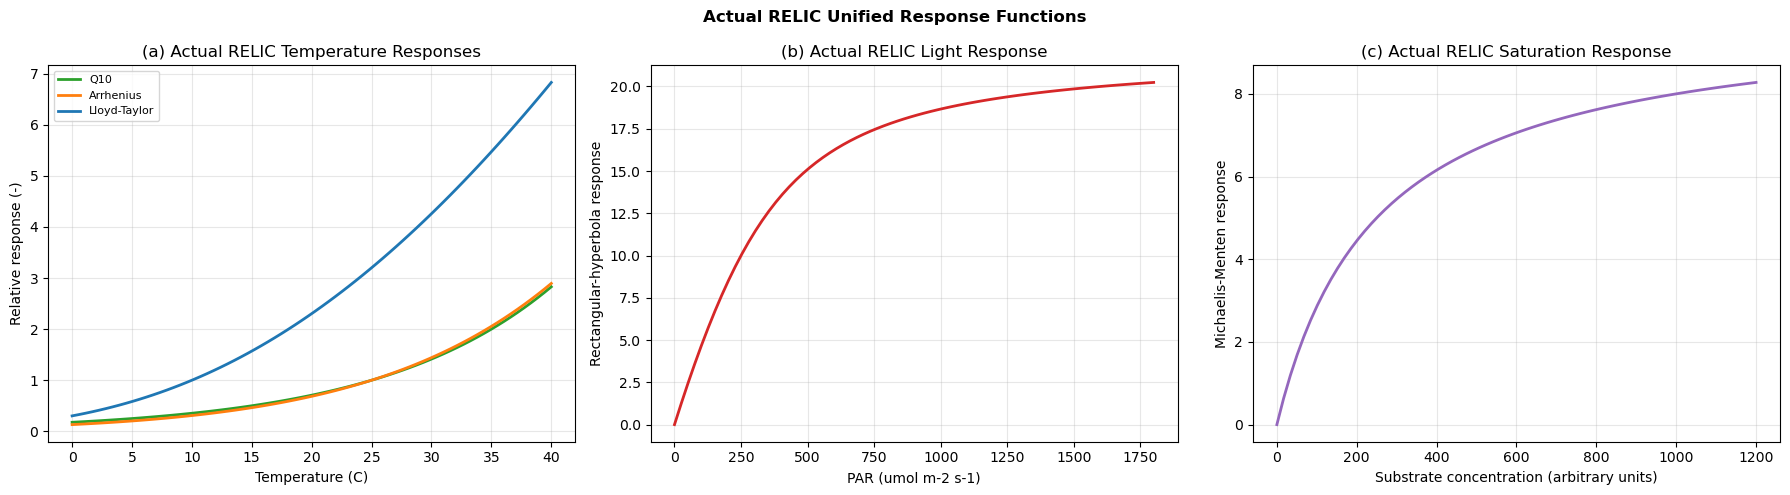

  Q10 response range: 0.177 to 2.828
  Arrhenius response range: 0.131 to 2.894
  Lloyd-Taylor response range: 0.302 to 6.828
  Light-response asymptote: 20.239
  Michaelis-Menten asymptote: 8.276


In [6]:
# Uses actual RELIC unified response functions rather than notebook-level response stubs.
from relic.utils.unified_response_functions import (
    arrhenius_temperature_response,
    lloyd_taylor_temperature_response,
    light_response_rectangular_hyperbola,
    michaelis_menten_response,
    q10_temperature_response,
)

# ---------------------------------------------------------------
# References:
#   Arrhenius (1889) -- temperature dependence of reaction rates
#   Lloyd and Taylor (1994) -- respiration temperature response
#   Farquhar and Wong (1984) -- rectangular-hyperbola light response
#   Michaelis and Menten (1913) -- saturation kinetics
# Mathematical expression:
#   f_Q10(T) = f_ref * Q10^((T - T_ref) / 10)
#   f_Arr(T) = f_ref * exp(Ea / R * (1 / T_ref - 1 / T))
#   A(I) = (alpha * I + Amax - sqrt((alpha * I + Amax)^2 - 4 * theta * alpha * I * Amax)) / (2 * theta)
#   v(S) = Vmax * S / (Km + S)
# Parameter meanings:
#   T_ref: reference temperature [K]
#   Q10: multiplicative response per 10 K warming [-]
#   Ea: activation energy [J mol-1]
#   alpha, Amax, theta: light-response efficiency, asymptote, and curvature
#   Km: half-saturation constant in the Michaelis-Menten curve
# ---------------------------------------------------------------

import torch
import matplotlib.pyplot as plt
%matplotlib inline

temperature_axis = torch.linspace(273.15, 313.15, 72, dtype=torch.float32)
q10_curve = q10_temperature_response(1.0, temperature_axis, 2.0).detach().cpu()
arrhenius_curve = arrhenius_temperature_response(1.0, temperature_axis, 55000.0).detach().cpu()
lloyd_taylor_curve = lloyd_taylor_temperature_response(1.0, temperature_axis, e0=308.56).detach().cpu()

light_axis = torch.linspace(0.0, 1800.0, 72, dtype=torch.float32)
light_curve = light_response_rectangular_hyperbola(
    light_axis,
    alpha=0.05,
    amax=torch.full_like(light_axis, 22.0),
    theta=0.7,
).detach().cpu()

substrate_axis = torch.linspace(0.0, 1200.0, 72, dtype=torch.float32)
michaelis_curve = michaelis_menten_response(
    substrate_axis,
    vmax=torch.full_like(substrate_axis, 10.0),
    km=250.0,
).detach().cpu()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot((temperature_axis - 273.15).tolist(), q10_curve.tolist(), color='tab:green', lw=2, label='Q10')
axes[0].plot((temperature_axis - 273.15).tolist(), arrhenius_curve.tolist(), color='tab:orange', lw=2, label='Arrhenius')
axes[0].plot((temperature_axis - 273.15).tolist(), lloyd_taylor_curve.tolist(), color='tab:blue', lw=2, label='Lloyd-Taylor')
axes[0].set_xlabel('Temperature (C)')
axes[0].set_ylabel('Relative response (-)')
axes[0].set_title('(a) Actual RELIC Temperature Responses')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].plot(light_axis.tolist(), light_curve.tolist(), color='tab:red', lw=2)
axes[1].set_xlabel('PAR (umol m-2 s-1)')
axes[1].set_ylabel('Rectangular-hyperbola response')
axes[1].set_title('(b) Actual RELIC Light Response')
axes[1].grid(True, alpha=0.3)

axes[2].plot(substrate_axis.tolist(), michaelis_curve.tolist(), color='tab:purple', lw=2)
axes[2].set_xlabel('Substrate concentration (arbitrary units)')
axes[2].set_ylabel('Michaelis-Menten response')
axes[2].set_title('(c) Actual RELIC Saturation Response')
axes[2].grid(True, alpha=0.3)

plt.suptitle('Actual RELIC Unified Response Functions', fontweight='bold')
plt.tight_layout()
plt.show()

print(f"  Q10 response range: {float(q10_curve.min().item()):.3f} to {float(q10_curve.max().item()):.3f}")
print(f"  Arrhenius response range: {float(arrhenius_curve.min().item()):.3f} to {float(arrhenius_curve.max().item()):.3f}")
print(f"  Lloyd-Taylor response range: {float(lloyd_taylor_curve.min().item()):.3f} to {float(lloyd_taylor_curve.max().item()):.3f}")
print(f"  Light-response asymptote: {float(light_curve.max().item()):.3f}")
print(f"  Michaelis-Menten asymptote: {float(michaelis_curve.max().item()):.3f}")

## Domain 5: Anthroposphere -- Management & Land Use

The anthroposphere captures human impacts: harvesting, fertilization,
irrigation, and land-use change.


The cell below only constructs the coordinator. Its forward call requires `soil_moisture`, `soil_nitrogen`, `soil_organic_carbon`, `crop_maturity`, `aboveground_biomass`, `air_temperature`, `irrigation_flux`, `harvest_flux`, `grazing_flux`, `co2_emission`, `field_capacity`, `wilting_point`, `evapotranspiration_flux`, and `precipitation_flux`. Irrigation demand uses the actual ET and precipitation fluxes; field capacity must exceed wilting point. A separately constructed `FireManagement` requires `config={'seed': <integer>}` with `0 <= seed < 2**63`.


In [7]:
# ---------------------------------------------------------------
# References:
#   Hurtt et al. (2011), Climatic Change -- land use harmonization
#   Pongratz et al. (2018) -- land management effects
# Mathematical expression:
#   C_harvest = f_harvest * C_above
#   N_fertilizer = application_rate * area
# Parameter meanings:
#   f_harvest: harvest fraction [dimensionless]
#   C_above: aboveground carbon pool [gC/m2]
# ---------------------------------------------------------------

# REAL RELIC functor: ManagementCoordinator
from relic.scientific.anthroposphere.management.coordinator import ManagementCoordinator
mgmt = ManagementCoordinator(
    name='management_coordinator',
)
print("=== Domain 5: Anthroposphere -- ManagementCoordinator ===")
print(f"  Class:     {type(mgmt).__name__}")
print(f"  Category:  {mgmt.metadata.category}")
print("[OK] ManagementCoordinator instantiated")

=== Domain 5: Anthroposphere -- ManagementCoordinator ===
  Class:     ManagementCoordinator
  Category:  ProcessCategory.SCALE_COUPLING
[OK] ManagementCoordinator instantiated


## Domain 6: Transport -- Diffusion & Advection Operators

Transport mechanisms move quantities between spatial locations:
turbulent diffusion, advection, and lateral exchange.


In [8]:
# ---------------------------------------------------------------
# References:
#   Fick (1855) -- diffusion law
#   RELIC transport: relic/scientific/transport/
# Mathematical expression:
#   dC/dt = D * d2C/dz2  (vertical diffusion, 1D)
#   Discretized: F_i = -D * (C_{i+1} - C_i) / dz
# Parameter meanings:
#   D: diffusion coefficient [m2/s]
#   dz: vertical grid spacing [m]
# ---------------------------------------------------------------

# REAL RELIC transport functors
from relic.scientific.transport import diffusion
print("=== Domain 6: Transport -- Diffusion ===")
avail = [x for x in dir(diffusion) if not x.startswith('_') and x[0].isupper()]
print(f"  Available classes: {avail}")
print("[OK] Transport module loaded")

=== Domain 6: Transport -- Diffusion ===
  Available classes: ['Any', 'CochainSpaceSpec', 'DIFFUSIVITY_LAYOUTS', 'Dict', 'DiffusivityError', 'ExecutionPhase', 'FickianDiffusion', 'FluxDict', 'FunctorMetadata', 'HodgeStarSpec', 'IPHSStructureSpec', 'Integral', 'List', 'Mapping', 'OperatorFactory', 'Optional', 'PortSpecIPHS', 'ProcessCategory', 'SUPPORTED_DIFFUSION_BOUNDARIES', 'Sequence', 'SpatialScale', 'StateDict', 'Tensor', 'TransportMechanismFunctor', 'Tuple', 'Union', 'UpdateItem', 'UpdateMode', 'VariableKind']
[OK] Transport module loaded


## Domain 7: Isotopes -- Fractionation & Tracing

RELIC exposes isotope numerical utilities. The public stable-isotope runtime is disabled while its governed ledger is unavailable; the later cell checks this explicit `[N]` boundary. Importing classes does not establish coupled isotope transport or tracking.


In [9]:
# ---------------------------------------------------------------
# References:
#   Craig (1954), J Geology -- isotope fractionation
#   Farquhar et al. (1989) -- carbon isotopes in photosynthesis
# Mathematical expression:
#   delta_13C_plant = delta_13C_atm - a - (b - a) * Ci/Ca
#   where a = 4.4 permil (diffusion), b = 27 permil (carboxylation)
# Parameter meanings:
#   delta_13C: isotopic ratio deviation from standard [permil]
#   a: diffusion fractionation [permil]
#   b: carboxylation fractionation [permil]
# ---------------------------------------------------------------

# REAL RELIC isotope functors
from relic.scientific import isotopes
print("=== Domain 7: Isotopes -- Fractionation ===")
avail = [x for x in dir(isotopes) if not x.startswith('_') and x[0].isupper()]
print(f"  Available classes: {avail}")
print("[OK] Isotopes module loaded")

=== Domain 7: Isotopes -- Fractionation ===
  Available classes: ['IsotopeConfig']
[OK] Isotopes module loaded


---
## Nutrient Cycling Theory

> **Reference:** `docs/source/theory/stoichiometry_constraint.md`,
> `phosphorus_cycle.md`, `nitrogen_leaching.md`


### N1. Stoichiometric Constraints (C:N:P)

> **Ref:** `stoichiometry_constraint.md`

**Liebig's Law of the Minimum:**

$$f_{\text{nutrient}} = \min\left(\frac{[N]}{[N]_{\text{crit}}}, \frac{[P]}{[P]_{\text{crit}}}, 1\right)$$

**Fixed C:N:P ratios** constrain allocation:

| Pool | C:N | C:P | N:P |
|------|:---:|:---:|:---:|
| Foliage | 25-40 | 500-800 | 15-25 |
| Fine roots | 40-60 | 800-1200 | 20-30 |
| Litter | 50-100 | 1000-2000 | 20-40 |
| SOM (humus) | 10-15 | 100-200 | 7-15 |
| Microbes | 8-12 | 40-80 | 5-8 |

**Nutrient mineralization** coupled to decomposition:

$$N_{\text{min}} = \frac{C_{\text{decomp}}}{(C/N)_{\text{substrate}}} - \frac{C_{\text{decomp}} \cdot \varepsilon}{(C/N)_{\text{microbe}}}$$

Negative $N_{\text{min}}$ = immobilization; positive = net mineralization.


StoichiometryConstraint: StoichiometryConstraint
  Target metabolic litter C:N = 15.00
  Flexibility = 0.200


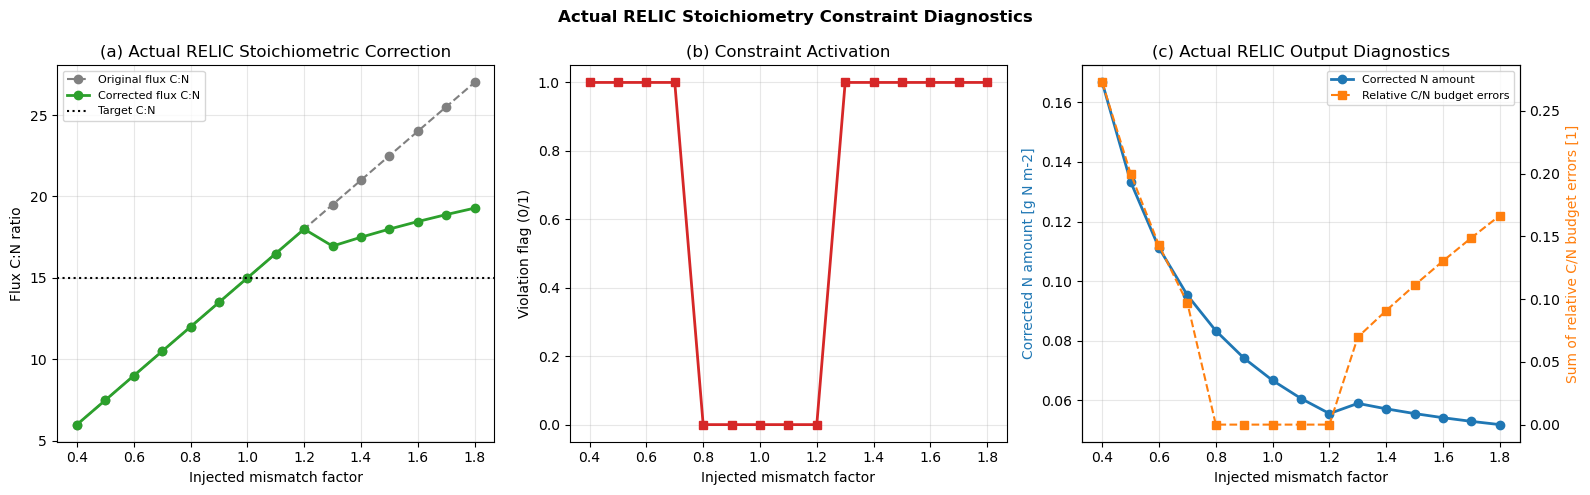

In [10]:
# Uses actual RELIC stoichiometric constraint diagnostics rather than a hand-built Liebig surface.
from relic.scientific.pedosphere.nutrient_cycling.stoichiometry import StoichiometryConstraint

# === Stoichiometric Constraints and Nutrient Coupling ===
# References:
#   Manzoni and Porporato (2009) -- substrate-decomposer stoichiometry
#   Cleveland and Liptzin (2007) -- soil C:N:P stoichiometry
# Formula implemented inside RELIC:
#   if |C_flux / N_flux - CN_target| / CN_target > flexibility, apply correction
# Parameters shown here:
#   CN_target: target pool C:N ratio [-]
#   flexibility: tolerated relative deviation [-]
#   correction_strength: relaxation toward target stoichiometry [-]

import torch
import matplotlib.pyplot as plt
%matplotlib inline

base_state = {
    'metabolic_litter_c': torch.tensor(10.0),
    'metabolic_litter_n': torch.tensor(0.5),
    'structural_litter_c': torch.tensor(50.0),
    'structural_litter_n': torch.tensor(1.0),
    'fast_som_c': torch.tensor(150.0),
    'fast_som_n': torch.tensor(10.0),
    'slow_som_c': torch.tensor(800.0),
    'slow_som_n': torch.tensor(50.0),
    'microbial_biomass_c': torch.tensor(10.0),
    'microbial_biomass_n': torch.tensor(1.2),
}

probe_functor = StoichiometryConstraint(name='nb18_stoich_probe')
target_cn = float(probe_functor.target_ratios['metabolic_litter'])
print('StoichiometryConstraint:', type(probe_functor).__name__)
print(f'  Target metabolic litter C:N = {target_cn:.2f}')
print(f'  Flexibility = {float(torch.as_tensor(probe_functor.flexibility)):.3f}')

mismatch_factors = torch.linspace(0.4, 1.8, 15)
original_cn = []
corrected_cn = []
violation_flags = []
mass_balance_error = []
corrected_n_fluxes = []

for idx, factor in enumerate(mismatch_factors):
    functor = StoichiometryConstraint(name=f'nb18_stoich_case_{idx}')
    c_flux = torch.tensor(1.0)
    n_flux = c_flux / torch.tensor(target_cn * float(factor))
    state = dict(base_state)
    state['diagnostics.carbon_fluxes'] = {'delta_metabolic_litter_c': c_flux}
    state['diagnostics.nitrogen_fluxes'] = {'delta_metabolic_litter_n': n_flux}
    state['diagnostics.carbon_inputs'] = c_flux
    state['diagnostics.nitrogen_inputs'] = n_flux
    state['diagnostics.carbon_outputs'] = torch.tensor(0.0)
    state['diagnostics.nitrogen_outputs'] = torch.tensor(0.0)
    output = functor.forward(state=state, time=0.0, dt=1.0)

    corrected_n = torch.as_tensor(output['diagnostics.stoichiometry_corrected_delta_metabolic_litter_n'], dtype=torch.float32)
    violation = torch.as_tensor(output['diagnostics.stoichiometry_metabolic_litter_violation'], dtype=torch.float32)
    total_error = torch.as_tensor(output['diagnostics.stoichiometry_mass_balance_error_total'], dtype=torch.float32)

    original_cn.append(float((c_flux / n_flux).item()))
    corrected_cn.append(float((c_flux / torch.clamp(corrected_n, min=1.0e-8)).item()))
    violation_flags.append(float(violation.item()))
    mass_balance_error.append(float(total_error.item()))
    corrected_n_fluxes.append(float(corrected_n.item()))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].plot(mismatch_factors.tolist(), original_cn, 'o--', color='gray', lw=1.5, label='Original flux C:N')
axes[0].plot(mismatch_factors.tolist(), corrected_cn, 'o-', color='tab:green', lw=2, label='Corrected flux C:N')
axes[0].axhline(target_cn, color='black', ls=':', lw=1.5, label='Target C:N')
axes[0].set_xlabel('Injected mismatch factor')
axes[0].set_ylabel('Flux C:N ratio')
axes[0].set_title('(a) Actual RELIC Stoichiometric Correction')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

axes[1].plot(mismatch_factors.tolist(), violation_flags, 's-', color='tab:red', lw=2)
axes[1].set_xlabel('Injected mismatch factor')
axes[1].set_ylabel('Violation flag (0/1)')
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_title('(b) Constraint Activation')
axes[1].grid(True, alpha=0.3)

balance_axis = axes[2].twinx()
axes[2].plot(mismatch_factors.tolist(), corrected_n_fluxes, 'o-', color='tab:blue', lw=2, label='Corrected N amount')
balance_axis.plot(mismatch_factors.tolist(), mass_balance_error, 's--', color='tab:orange', lw=1.5, label='Relative C/N budget errors')
axes[2].set_xlabel('Injected mismatch factor')
axes[2].set_ylabel('Corrected N amount [g N m-2]', color='tab:blue')
balance_axis.set_ylabel('Sum of relative C/N budget errors [1]', color='tab:orange')
axes[2].set_title('(c) Actual RELIC Output Diagnostics')
left_handles, left_labels = axes[2].get_legend_handles_labels()
right_handles, right_labels = balance_axis.get_legend_handles_labels()
axes[2].legend(left_handles + right_handles, left_labels + right_labels, fontsize=8)
axes[2].grid(True, alpha=0.3)

plt.suptitle('Actual RELIC Stoichiometry Constraint Diagnostics', fontweight='bold')
plt.tight_layout()
plt.show()


### N2. Phosphorus Cycle

> **Ref:** `phosphorus_cycle.md`

The following Langmuir curve and flow sketch are pedagogical illustrations; they do not execute a RELIC phosphorus-cycle Functor or verify its budget. The numerical values in the illustration are teaching choices, not calibrated model parameters.

**P pools:** labile P, organic P, occluded P, mineral P, plant P

**Sorption isotherm** (Langmuir):

$$P_{\text{sorbed}} = \frac{P_{\max} \cdot K_L \cdot [P]}{1 + K_L \cdot [P]}$$

**Weathering release:**

$$W_P = k_w \cdot \exp\left(\frac{E_a}{R}\left(\frac{1}{T_{\text{ref}}} - \frac{1}{T}\right)\right) \cdot P_{\text{mineral}}$$


StoichiometryConstraint Functor: StoichiometryConstraint


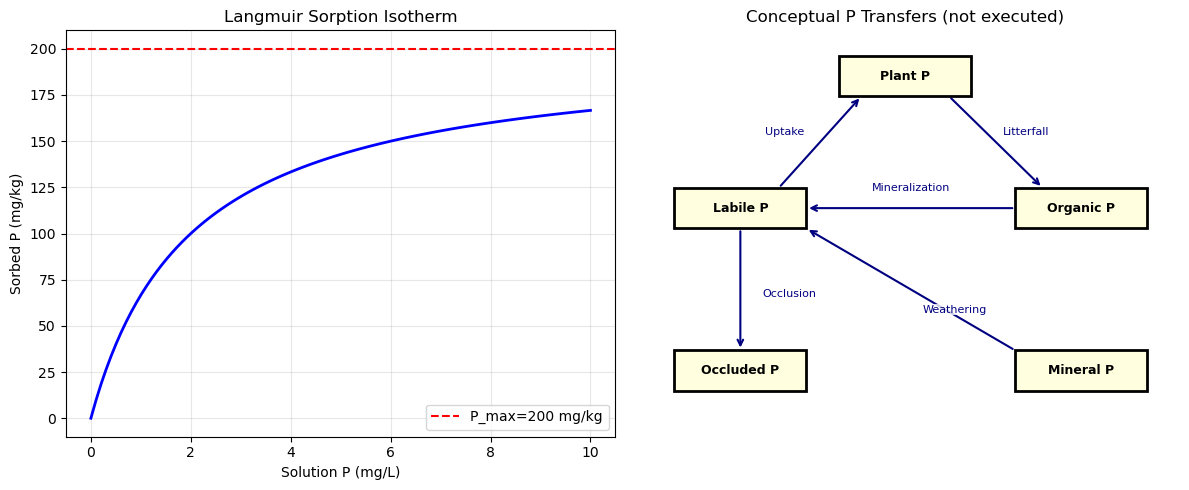

In [11]:
# Uses relic.scientific.pedosphere.nutrient_cycling.stoichiometry.StoichiometryConstraint
from relic.scientific.pedosphere.nutrient_cycling.stoichiometry import StoichiometryConstraint
print('StoichiometryConstraint Functor:', StoichiometryConstraint.__name__)
# === Phosphorus Cycle ===
# References: Langmuir (1918); phosphorus_cycle.md (illustration only).
# Mathematical expression: P_sorbed = P_max * K_L * P_solution / (1 + K_L * P_solution).
# Parameter meanings: P_max is illustrative sorption capacity; K_L is affinity.
# Units: solution [mg L-1], sorbed [mg kg-1], K_L [L mg-1].
# Domain/constraints: nonnegative solution concentration; positive teaching constants.
# Sign convention: positive values denote sorbed phosphorus, not a state update.

P_solution = torch.linspace(0, 10, 100)  # mg/L
P_max = 200  # mg/kg
K_L = 0.5    # L/mg
P_sorbed = P_max * K_L * P_solution / (1 + K_L * P_solution)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(P_solution, P_sorbed, 'b-', lw=2)
axes[0].axhline(P_max, color='red', ls='--', label='P_max=%d mg/kg' % P_max)
axes[0].set_xlabel('Solution P (mg/L)')
axes[0].set_ylabel('Sorbed P (mg/kg)')
axes[0].set_title('Langmuir Sorption Isotherm')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Conceptual transfer directions follow phosphorus_cycle.md available-P balance.
# This panel is a schematic only; it computes no phosphorus process or state update.
axes[1].set_xlim(0, 10)
axes[1].set_ylim(0, 8)
axes[1].axis('off')
pools_p = {'Plant P': (5.0, 7.1), 'Labile P': (2.0, 4.5), 'Organic P': (8.2, 4.5),
           'Occluded P': (2.0, 1.3), 'Mineral P': (8.2, 1.3)}
for name, (x, y) in pools_p.items():
    axes[1].add_patch(plt.Rectangle((x-1.2, y-0.4), 2.4, 0.8, facecolor='lightyellow',
                                     edgecolor='black', lw=2, zorder=5))
    axes[1].text(x, y, name, ha='center', va='center', fontsize=9, fontweight='bold', zorder=6)
flows_p = [
    ((2.7, 4.9), (4.2, 6.7), 'Uptake', (2.8, 6.0)),
    ((5.8, 6.7), (7.5, 4.9), 'Litterfall', (7.2, 6.0)),
    ((7.0, 4.5), (3.2, 4.5), 'Mineralization', (5.1, 4.9)),
    ((7.0, 1.7), (3.2, 4.1), 'Weathering', (5.9, 2.5)),
    ((2.0, 4.1), (2.0, 1.7), 'Occlusion', (2.9, 2.8)),
]
for start_point, end_point, label, label_point in flows_p:
    axes[1].annotate('', xy=end_point, xytext=start_point,
                     arrowprops=dict(arrowstyle='->', color='navy', lw=1.5))
    axes[1].text(*label_point, label, fontsize=8, color='navy', ha='center', va='center',
                 bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=0.5))
axes[1].set_title('Conceptual P Transfers (not executed)')
plt.tight_layout()
plt.show()


### N3. Nitrogen Leaching

> **Ref:** `nitrogen_leaching.md`

The canonical input `drainage_flux` is a water mass flux, not a drainage velocity:

$$q=\frac{F_{\mathrm{water}}}{\rho_w},\quad
C_{\mathrm{NO3}}=\frac{N_{\mathrm{NO3}}}{\theta z},\quad
f_{\mathrm{mobile}}=\frac{1}{1+\rho_b K_d/\theta},\quad
F_N=qC_{\mathrm{NO3}}f_{\mathrm{mobile}}.$$

`soil_depth` and `bulk_density` are explicit forcing inputs. The production Functor also applies its configured export-time and donor-pool limits. Water flux uses `kg m-2 s-1`, nitrate concentration uses `g N m-3`, and nitrate export uses `g N m-2 s-1`.


NitrogenLeachingProcess: NitrogenLeachingProcess


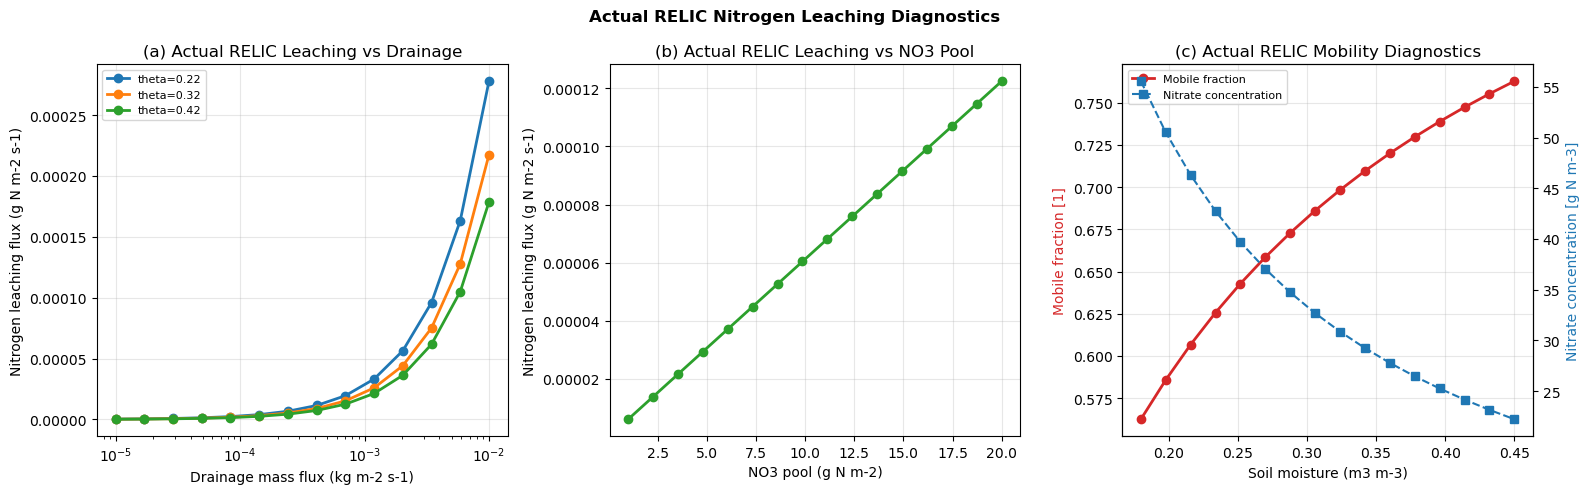

In [12]:
# Uses actual RELIC nitrogen leaching transport instead of a notebook-level q*C sketch.
from relic.scientific.pedosphere.nutrient_cycling.nitrogen_leaching import NitrogenLeachingProcess

# === Nitrogen Leaching ===
# References:
#   Biome-BGC nleaching.c mobile nitrogen formulation
#   Cameron and Haynes (1986) -- nitrogen mobility and retention
# Mathematical expression:
#   F_N = Q_drain * C_NO3 * mobile_fraction
# Parameter meanings:
#   drainage_flux: downward water mass flux [kg m-2 s-1]
#   no3_nitrogen: nitrate pool [g N m-2]
#   soil_moisture: volumetric water content [m3 m-3]; soil_depth [m].
# Units: nitrate pool [g N m-2]; concentration [g N m-3]; export [g N m-2 s-1].
# Domain/constraints: soil_depth and bulk_density positive; 0 < soil_moisture <= 1.
# Sign convention: positive leaching exports nitrate from the soil donor.

import torch
import matplotlib.pyplot as plt
%matplotlib inline

print('NitrogenLeachingProcess:', NitrogenLeachingProcess.__name__)


def run_leaching_case(no3_n: float, soil_moisture: float, drainage_flux: float, dt: float = 3600.0) -> dict:
    functor = NitrogenLeachingProcess(name='nb18_n_leach_case')
    updates = functor.forward(
        state={
            'no3_nitrogen': torch.tensor(no3_n, dtype=torch.float32),
            'nh4_nitrogen': torch.tensor(5.0, dtype=torch.float32),
            'soil_moisture': torch.tensor(soil_moisture, dtype=torch.float32),
            'drainage_flux': torch.tensor(drainage_flux, dtype=torch.float32),
            'bulk_density': torch.tensor(1400.0, dtype=torch.float32),
            'soil_depth': torch.tensor(1.0, dtype=torch.float32),
            'porosity': torch.tensor(0.45, dtype=torch.float32),
            'soil_temperature': torch.tensor(293.15, dtype=torch.float32),
        },
        time=0.0,
        dt=dt,
    )
    return {k: (v.value if hasattr(v, 'value') else v) for k, v in updates.items()}


drainage_values = torch.logspace(-5, -2, 14)
moisture_levels = [0.22, 0.32, 0.42]
flux_curves = []
for theta in moisture_levels:
    fluxes = []
    for drainage in drainage_values:
        updates = run_leaching_case(no3_n=10.0, soil_moisture=theta, drainage_flux=float(drainage.item()))
        fluxes.append(float(torch.as_tensor(updates['nitrogen_leaching_flux']).item()))
    flux_curves.append(fluxes)

no3_values = torch.linspace(1.0, 20.0, 16)
flux_vs_no3 = []
for no3_pool in no3_values:
    updates = run_leaching_case(no3_n=float(no3_pool.item()), soil_moisture=0.35, drainage_flux=3.0e-3)
    flux_vs_no3.append(float(torch.as_tensor(updates['nitrogen_leaching_flux']).item()))

moisture_scan = torch.linspace(0.18, 0.45, 16)
mobile_fraction_scan = []
nitrate_concentration_scan = []
for theta in moisture_scan:
    updates = run_leaching_case(no3_n=10.0, soil_moisture=float(theta.item()), drainage_flux=3.0e-3)
    mobile_fraction_scan.append(float(torch.as_tensor(updates['diagnostics.nitrogen_leaching.mobile_fraction']).item()))
    nitrate_concentration_scan.append(float(torch.as_tensor(updates['diagnostics.nitrogen_leaching.nitrate_concentration']).item()))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for theta, fluxes in zip(moisture_levels, flux_curves):
    axes[0].plot(drainage_values.tolist(), fluxes, 'o-', lw=2, label=f'theta={theta:.2f}')
axes[0].set_xscale('log')
axes[0].set_xlabel('Drainage mass flux (kg m-2 s-1)')
axes[0].set_ylabel('Nitrogen leaching flux (g N m-2 s-1)')
axes[0].set_title('(a) Actual RELIC Leaching vs Drainage')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

axes[1].plot(no3_values.tolist(), flux_vs_no3, 'o-', color='tab:green', lw=2)
axes[1].set_xlabel('NO3 pool (g N m-2)')
axes[1].set_ylabel('Nitrogen leaching flux (g N m-2 s-1)')
axes[1].set_title('(b) Actual RELIC Leaching vs NO3 Pool')
axes[1].grid(True, alpha=0.3)

concentration_axis = axes[2].twinx()
axes[2].plot(moisture_scan.tolist(), mobile_fraction_scan, 'o-', color='tab:red', lw=2, label='Mobile fraction')
concentration_axis.plot(moisture_scan.tolist(), nitrate_concentration_scan, 's--', color='tab:blue', lw=1.5, label='Nitrate concentration')
axes[2].set_xlabel('Soil moisture (m3 m-3)')
axes[2].set_ylabel('Mobile fraction [1]', color='tab:red')
concentration_axis.set_ylabel('Nitrate concentration [g N m-3]', color='tab:blue')
axes[2].set_title('(c) Actual RELIC Mobility Diagnostics')
left_handles, left_labels = axes[2].get_legend_handles_labels()
right_handles, right_labels = concentration_axis.get_legend_handles_labels()
axes[2].legend(left_handles + right_handles, left_labels + right_labels, fontsize=8)
axes[2].grid(True, alpha=0.3)

plt.suptitle('Actual RELIC Nitrogen Leaching Diagnostics', fontweight='bold')
plt.tight_layout()
plt.show()


---
## Atmosphere Process Theory

> **Reference:** `docs/source/theory/eddy_diffusion_blm.md`, `dry_deposition_aggregator.md`


### A1. Eddy Diffusion & Boundary Layer Meteorology

> **Ref:** `eddy_diffusion_blm.md`

**Turbulent diffusivity** profile in the surface layer:

$$K_z = \frac{\kappa \cdot u_* \cdot z}{\phi_h(z/L)}$$

where $\kappa = 0.41$ (von Karman), $u_*$ = friction velocity,
$\phi_h$ = stability function, $L$ = Obukhov length.

**Stability regimes:**

| $z/L$ | Regime | $\phi_h$ |
|:---:|:---:|:---:|
| < -0.1 | Unstable | $(1-16z/L)^{-0.5}$ |
| $\approx 0$ | Neutral | $1.0$ |
| > 0.1 | Stable | $1 + 5z/L$ |

**Aerodynamic resistance:**

$$r_a = \frac{\ln(z/z_0) - \psi_m(z/L)}{\kappa \cdot u_*}$$


EddyDiffusionBLM Functor: EddyDiffusionBLMFunctor
  Tutorial diagnostic dt=45.0 s
  Unstable K_used=50.000 m2 s-1 | z/L=-2.000 | stability_number=0.004
  Neutral  K_used=49.200 m2 s-1 | z/L=0.000 | stability_number=0.003
  Stable   K_used=4.473 m2 s-1 | z/L=2.000 | stability_number=0.000


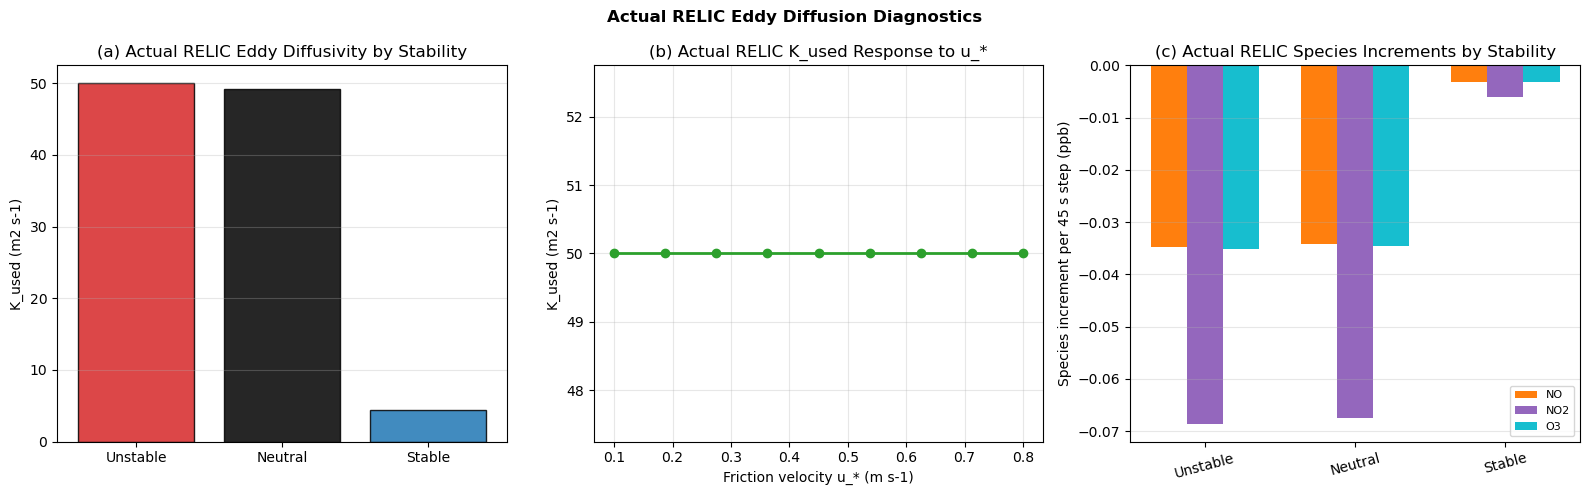

  K_used range: 4.473 to 50.000 m2 s-1
  Stability-number range: 0.000 to 0.004
  NO increment range: -0.0348 to -0.0031 ppb per step


In [13]:
# Uses actual RELIC transport functor and diagnostics rather than a hand-written formula.
from relic.scientific.atmosphere.transport import EddyDiffusionBLM
from relic.scientific.atmosphere.transport.eddy_diffusion_blm import EddyDiffusionConfig

print('EddyDiffusionBLM Functor:', EddyDiffusionBLM.__name__)

# ---------------------------------------------------------------
# References:
#   atmosphere_eddy_diffusion_blm.md
#   Holton and Hakim (2012) -- K-theory for boundary-layer diffusion
#   Oran and Boris (1987) -- explicit diffusion stability guidance
# Mathematical expression:
#   dC/dt = d/dz[K(z) dC/dz] - C/h + S
#   Stability number = K * dt / dz^2
# Parameter meanings:
#   K_used: effective eddy diffusivity [m2 s-1]
#   u_star_used: friction velocity [m s-1]
#   monin_obukhov_length: stability length [m]
#   pbl_height_used: boundary layer height [m]
# ---------------------------------------------------------------

import torch
import matplotlib.pyplot as plt
%matplotlib inline

base_state = {
    'air_temperature': torch.tensor(298.15),
    'no_mixing_ratio': torch.tensor(10e-9),
    'no2_mixing_ratio': torch.tensor(20e-9),
    'o3_mixing_ratio': torch.tensor(50e-9),
    'isoprene_mixing_ratio': torch.tensor(2e-9),
    'pbl_height': torch.tensor(800.0),
    'friction_velocity': torch.tensor(0.30),
    'monin_obukhov_length': torch.tensor(-200.0),
}


def build_eddy_functor(name: str) -> EddyDiffusionBLM:
    return EddyDiffusionBLM(
        name=name,
        transport_config=EddyDiffusionConfig(enabled=True),
    )


stability_cases = [
    ('Unstable', -200.0, 'tab:red'),
    ('Neutral', 1.0e9, 'black'),
    ('Stable', 50.0, 'tab:blue'),
]

# Keep the explicit diffusion update below the most restrictive CFL suggestion.
stable_dt = 45.0
print(f"  Tutorial diagnostic dt={stable_dt:.1f} s")

k_used_values = []
stability_numbers = []
for label, monin_length, _color in stability_cases:
    eddy = build_eddy_functor(name=f'nb18_eddy_{label.lower()}')
    case_state = dict(base_state)
    case_state['monin_obukhov_length'] = torch.tensor(monin_length)
    output = eddy.forward(
        state=case_state,
        time=0.0,
        dt=stable_dt,
    )
    k_used = unwrap_update(output['diagnostics.eddy_diffusion.eddy_diffusivity'])
    stability_number = unwrap_update(output['diagnostics.eddy_diffusion.stability_number'])
    stability_parameter = unwrap_update(output['diagnostics.eddy_diffusion.stability_parameter_z_over_L'])
    k_used_values.append(float(k_used))
    stability_numbers.append(float(stability_number))
    print(
        f"  {label:<8s} K_used={float(k_used):.3f} m2 s-1 | "
        f"z/L={float(stability_parameter):.3f} | "
        f"stability_number={float(stability_number):.3f}"
    )

u_star_values = torch.linspace(0.10, 0.80, 9)
k_vs_ustar = []
for idx, u_star in enumerate(u_star_values):
    eddy = build_eddy_functor(name=f'nb18_eddy_ustar_{idx}')
    case_state = dict(base_state)
    case_state['friction_velocity'] = u_star
    output = eddy.forward(
        state=case_state,
        time=float(idx),
        dt=stable_dt,
    )
    k_vs_ustar.append(float(unwrap_update(output['diagnostics.eddy_diffusion.eddy_diffusivity'])))

case_names = [item[0] for item in stability_cases]
stability_tendencies = {'NO': [], 'NO2': [], 'O3': []}
for label, monin_length, _color in stability_cases:
    eddy = build_eddy_functor(name=f'nb18_eddy_increment_{label.lower()}')
    case_state = dict(base_state)
    case_state['monin_obukhov_length'] = torch.tensor(monin_length)
    output = eddy.forward(
        state=case_state,
        time=0.0,
        dt=stable_dt,
    )
    stability_tendencies['NO'].append(float(unwrap_update(output['no_mixing_ratio'])) * 1.0e9)
    stability_tendencies['NO2'].append(float(unwrap_update(output['no2_mixing_ratio'])) * 1.0e9)
    stability_tendencies['O3'].append(float(unwrap_update(output['o3_mixing_ratio'])) * 1.0e9)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

labels = [item[0] for item in stability_cases]
colors = [item[2] for item in stability_cases]
axes[0].bar(labels, k_used_values, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_ylabel('K_used (m2 s-1)')
axes[0].set_title('(a) Actual RELIC Eddy Diffusivity by Stability')
axes[0].grid(True, axis='y', alpha=0.3)

axes[1].plot(u_star_values.tolist(), k_vs_ustar, 'o-', color='tab:green', lw=2)
axes[1].set_xlabel('Friction velocity u_* (m s-1)')
axes[1].set_ylabel('K_used (m2 s-1)')
axes[1].set_title('(b) Actual RELIC K_used Response to u_*')
axes[1].grid(True, alpha=0.3)

x = torch.arange(len(case_names), dtype=torch.float32).tolist()
width = 0.24
axes[2].bar([item - width for item in x], stability_tendencies['NO'], width=width, label='NO', color='tab:orange')
axes[2].bar(x, stability_tendencies['NO2'], width=width, label='NO2', color='tab:purple')
axes[2].bar([item + width for item in x], stability_tendencies['O3'], width=width, label='O3', color='tab:cyan')
axes[2].set_xticks(x)
axes[2].set_xticklabels(case_names, rotation=15)
axes[2].set_ylabel(f'Species increment per {stable_dt:.0f} s step (ppb)')
axes[2].set_title('(c) Actual RELIC Species Increments by Stability')
axes[2].grid(True, axis='y', alpha=0.3)
axes[2].legend(fontsize=8)

plt.suptitle('Actual RELIC Eddy Diffusion Diagnostics', fontweight='bold')
plt.tight_layout()
plt.show()

print(f"  K_used range: {min(k_used_values):.3f} to {max(k_used_values):.3f} m2 s-1")
print(f"  Stability-number range: {min(stability_numbers):.3f} to {max(stability_numbers):.3f}")
print(f"  NO increment range: {min(stability_tendencies['NO']):.4f} to {max(stability_tendencies['NO']):.4f} ppb per step")

### A2. Dry Deposition

> **Ref:** `dry_deposition_aggregator.md`

The current aggregator uses one resistance law with species-specific effective surface resistance:

$$v_{d,s}=\frac{1}{r_a+r_{\mathrm{eff},s}},\qquad
\Delta\chi_s=\max\left(-\chi_s,-\frac{v_{d,s}\chi_s\Delta t}{h_{\mathrm{pbl}}}\right).$$

The cell checks actual increments against this analytic expression. Its hourly-equivalent removal rates are rescaled from a 1800 s diagnostic call; they are not a second integration.


DryDepositionAggregator: DryDepositionAggregator


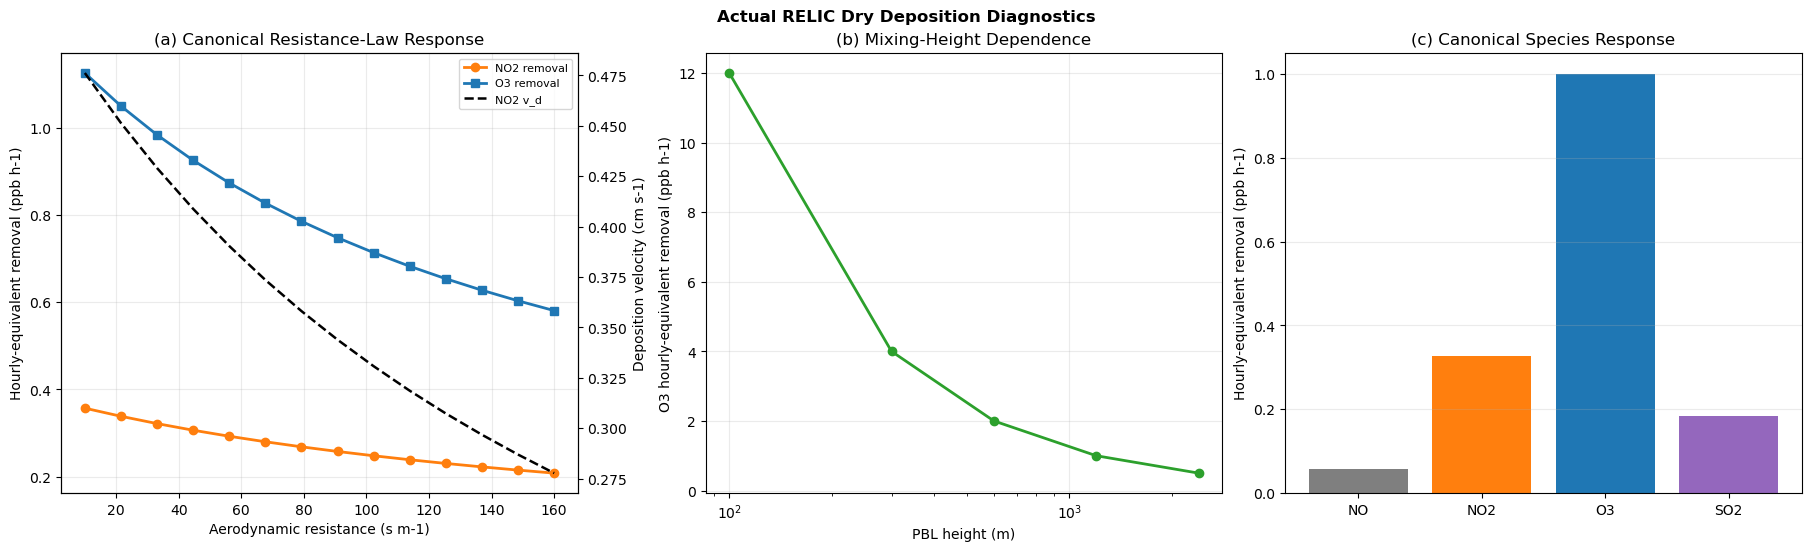

  O3 removal range: 0.580645 to 1.125000 ppb h-1
  NO2 deposition velocity range: 0.2778 to 0.4762 cm s-1
  Analytic increment oracle max error: 0.000e+00


In [14]:
# Uses the canonical RELIC resistance-law dry deposition transport.
from relic.scientific.atmosphere.transport.dry_deposition_aggregator import (
    DryDepositionAggregator,
    DryDepositionConfig,
)
from relic.utils.time_constants import SECONDS_PER_HOUR

# === Dry Deposition ===
# References:
#   Wesely (1989) -- dry deposition resistance framework
#   Zhang et al. (2003) -- revised gaseous dry deposition parameterization
# Mathematical expression:
#   v_d,s = 1 / (r_a + r_eff,s)
#   Delta C_s = max(-C_s, -v_d,s * C_s * dt / h_pbl)
# Parameter meanings:
#   r_a: aerodynamic resistance [s m-1]
#   r_eff,s: species effective non-aerodynamic resistance [s m-1]
#   h_pbl: planetary boundary-layer height [m]
#   C_s: atmospheric mixing ratio [mol mol-1]
# Units: v_d [m s-1], Delta C_s [mol mol-1] per step.
# Domain/constraints: resistances, h_pbl, and dt are finite and positive; C_s is finite and non-negative.
# Sign convention: negative Delta C_s is removal from the atmosphere through the surface-export port.

import torch
import matplotlib.pyplot as plt
%matplotlib inline

print('DryDepositionAggregator:', DryDepositionAggregator.__name__)

DT_DEPOSITION = 1800.0
SECONDS_PER_HOUR_VALUE = float(SECONDS_PER_HOUR)
BASE_MIXING_RATIOS = {
    'no': 10.0e-9,
    'no2': 25.0e-9,
    'o3': 60.0e-9,
    'so2': 8.0e-9,
}


def tensor_scalar(value):
    raw = value.value if hasattr(value, 'value') else value
    return float(torch.as_tensor(raw, dtype=torch.float64).reshape(-1)[0].item())


def run_deposition_case(case_id: int, aerodynamic_resistance: float, pbl_height: float) -> dict:
    functor = DryDepositionAggregator(
        name=f'nb18_dep_{case_id}',
        deposition_config=DryDepositionConfig(enabled=True),
    )
    state = {
        'no_mixing_ratio': torch.tensor(BASE_MIXING_RATIOS['no'], dtype=torch.float64),
        'no2_mixing_ratio': torch.tensor(BASE_MIXING_RATIOS['no2'], dtype=torch.float64),
        'o3_mixing_ratio': torch.tensor(BASE_MIXING_RATIOS['o3'], dtype=torch.float64),
        'so2_mixing_ratio': torch.tensor(BASE_MIXING_RATIOS['so2'], dtype=torch.float64),
        'pbl_height': torch.tensor(float(pbl_height), dtype=torch.float64),
        'aerodynamic_resistance': torch.tensor(float(aerodynamic_resistance), dtype=torch.float64),
    }
    updates = functor.forward(state=state, time=float(case_id), dt=DT_DEPOSITION)
    result = {'analytic_error': 0.0, 'velocity_cm_s': {}}
    for species, concentration in BASE_MIXING_RATIOS.items():
        resistance = functor.species_parameters[species].effective_resistance
        velocity = 1.0 / (aerodynamic_resistance + resistance)
        raw_increment = -velocity * concentration * DT_DEPOSITION / pbl_height
        expected_increment = max(-concentration, min(0.0, raw_increment))
        actual_increment = tensor_scalar(updates[f'{species}_mixing_ratio'])
        tolerance = max(1.0e-18, abs(expected_increment) * 1.0e-10)
        assert abs(actual_increment - expected_increment) <= tolerance
        result[f'{species}_increment'] = actual_increment
        result['velocity_cm_s'][species] = velocity * 100.0
        result['analytic_error'] = max(result['analytic_error'], abs(actual_increment - expected_increment))
    return result


aerodynamic_values = torch.linspace(10.0, 160.0, 14)
no2_removal_ppbph = []
o3_removal_ppbph = []
no2_velocity_cmps = []
analytic_errors = []
for idx, aerodynamic_resistance in enumerate(aerodynamic_values.tolist()):
    result = run_deposition_case(idx, aerodynamic_resistance, pbl_height=1200.0)
    hourly_scale = SECONDS_PER_HOUR_VALUE / DT_DEPOSITION
    no2_removal_ppbph.append(abs(result['no2_increment']) * 1.0e9 * hourly_scale)
    o3_removal_ppbph.append(abs(result['o3_increment']) * 1.0e9 * hourly_scale)
    no2_velocity_cmps.append(result['velocity_cm_s']['no2'])
    analytic_errors.append(result['analytic_error'])

height_values = torch.tensor([100.0, 300.0, 600.0, 1200.0, 2400.0], dtype=torch.float32)
height_response = []
for idx, height in enumerate(height_values.tolist()):
    result = run_deposition_case(100 + idx, aerodynamic_resistance=30.0, pbl_height=height)
    height_response.append(abs(result['o3_increment']) * 1.0e9 * SECONDS_PER_HOUR_VALUE / DT_DEPOSITION)
    analytic_errors.append(result['analytic_error'])

reference_result = run_deposition_case(200, aerodynamic_resistance=30.0, pbl_height=1200.0)
species_names = ['no', 'no2', 'o3', 'so2']
species_removal_ppbph = [
    abs(reference_result[f'{species}_increment']) * 1.0e9 * SECONDS_PER_HOUR_VALUE / DT_DEPOSITION
    for species in species_names
]
analytic_errors.append(reference_result['analytic_error'])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.4), constrained_layout=True)

ax_left = axes[0]
ax_right = ax_left.twinx()
ax_left.plot(aerodynamic_values.tolist(), no2_removal_ppbph, 'o-', color='tab:orange', lw=2.0, label='NO2 removal')
ax_left.plot(aerodynamic_values.tolist(), o3_removal_ppbph, 's-', color='tab:blue', lw=2.0, label='O3 removal')
ax_right.plot(aerodynamic_values.tolist(), no2_velocity_cmps, '--', color='black', lw=1.8, label='NO2 v_d')
ax_left.set_xlabel('Aerodynamic resistance (s m-1)')
ax_left.set_ylabel('Hourly-equivalent removal (ppb h-1)')
ax_right.set_ylabel('Deposition velocity (cm s-1)')
ax_left.set_title('(a) Canonical Resistance-Law Response')
ax_left.grid(True, alpha=0.25)
left_handles, left_labels = ax_left.get_legend_handles_labels()
right_handles, right_labels = ax_right.get_legend_handles_labels()
ax_left.legend(left_handles + right_handles, left_labels + right_labels, loc='upper right', fontsize=8)

axes[1].plot(height_values.tolist(), height_response, 'o-', color='tab:green', lw=2.0)
axes[1].set_xscale('log')
axes[1].set_xlabel('PBL height (m)')
axes[1].set_ylabel('O3 hourly-equivalent removal (ppb h-1)')
axes[1].set_title('(b) Mixing-Height Dependence')
axes[1].grid(True, alpha=0.25)

axes[2].bar([name.upper() for name in species_names], species_removal_ppbph, color=['tab:gray', 'tab:orange', 'tab:blue', 'tab:purple'])
axes[2].set_ylabel('Hourly-equivalent removal (ppb h-1)')
axes[2].set_title('(c) Canonical Species Response')
axes[2].grid(True, axis='y', alpha=0.25)

plt.suptitle('Actual RELIC Dry Deposition Diagnostics', fontweight='bold')
plt.show()

max_analytic_error = max(analytic_errors)
assert max_analytic_error <= 1.0e-18
print(f"  O3 removal range: {min(o3_removal_ppbph):.6f} to {max(o3_removal_ppbph):.6f} ppb h-1")
print(f"  NO2 deposition velocity range: {min(no2_velocity_cmps):.4f} to {max(no2_velocity_cmps):.4f} cm s-1")
print(f"  Analytic increment oracle max error: {max_analytic_error:.3e}")

---
## Wetland Methane Emissions

> **Reference:** `docs/source/theory/wetland_methane.md`

The kernels report instantaneous carbon-basis rates in `g C m-2 s-1`; plots convert these rates to `mg C m-2 h-1`.

**Production** combines iMAPLE and a separate calibrated RELIC branch:
$$P_i=R_h r f_T f_{\mathrm{pH}} f_{\mathrm{wet}},\quad
P_c=R_h r f_T f_{Eh}A,\quad P=(1-w)P_i+wP_c.$$

The release ratio is $r=0.2$ from the iMAPLE code release; Yue et al. (2024) Eq. 34 does not print its numerical value. The Zhu et al. (2014) peak temperature factor uses Yue Eq. 39:
$$Q_{10}(T)=\mathrm{clip}\left(3(1.33)^{(T-298.15)/10},1.7,16\right).$$
Wetland fraction is continuous, without an activation floor or the removed 6.45 multiplier. The calibrated branch is an Rh-based empirical expression, not faithful DNDC substrate kinetics. Branch diagnostics are `diagnostics.methane_production.imaple_rate` and `diagnostics.methane_production.calibrated_rate`.

**Oxidation** follows Riley et al. (2011), Eq. 7, with CLM4.5 layer conventions:
$$C_{\mathrm{CH4}}=\frac{M}{M_C z\phi\,WFPS},\qquad
O=\min\left(R_{\max}\frac{C_{\mathrm{CH4}}}{K_{\mathrm{CH4}}+C_{\mathrm{CH4}}}
\frac{C_{\mathrm{O2}}}{K_{\mathrm{O2}}+C_{\mathrm{O2}}}
1.9^{(T-285.15)/10}zM_C,\frac{M}{\Delta t}\right).$$

Oxidation has no Eh gate or branch weight. This wetland-layer law uses a moisture factor of one; the unsaturated matric-potential response is not implemented. The surface below varies oxygen and temperature at fixed storage, porosity, and WFPS. Kinetic demand and unmet storage-limited demand have separate diagnostics.

**Transport** returns diffusion, ebullition, and plant-mediated pathway rates. These separate kernel probes do not advance a shared methane budget or validate a coupled production-oxidation-transport run.


MethaneProductionFunctor: MethaneProductionFunctor
MethaneOxidationFunctor: MethaneOxidationFunctor
MethaneTransportFunctor: MethaneTransportFunctor
  Reference heterotrophic respiration: 5.50 g C m-2 day-1
  Display units: mg C m-2 h-1 converted from actual RELIC carbon-basis rate diagnostics


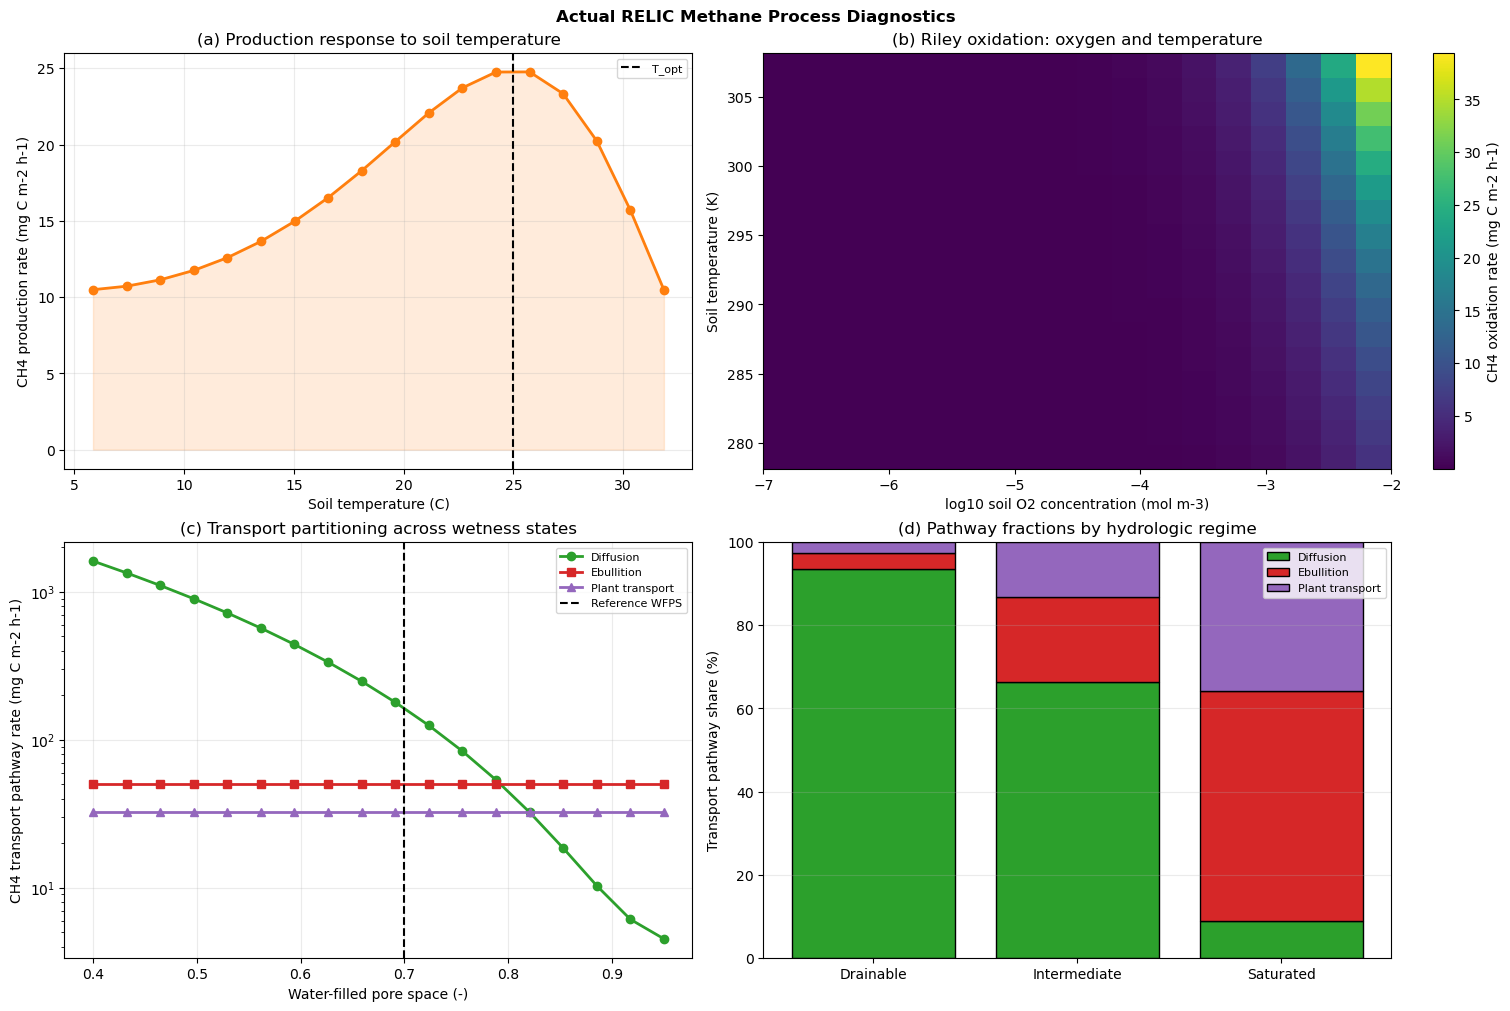

  Production range: 10.5 to 24.8 mg C m-2 h-1
  Oxidation response surface range: 0.0 to 39.4 mg C m-2 h-1
  Diffusion range: 4.5 to 1613.8 mg C m-2 h-1
  Ebullition range: 50.0 to 50.0 mg C m-2 h-1
  Plant transport range: 32.4 to 32.4 mg C m-2 h-1


In [15]:
# Uses actual RELIC methane production, oxidation, and transport functors rather than notebook-defined formulas.
from relic.scientific.pedosphere.methane import (
    MethaneProductionFunctor,
    MethaneOxidationFunctor,
    MethaneTransportFunctor,
)
from relic.utils.time_constants import SECONDS_PER_DAY, SECONDS_PER_HOUR
from relic.utils.physical_constants import get_physical_constant

# ---------------------------------------------------------------
# References:
#   Yue et al. (2024), Eqs. 34 and 39; Zhu et al. (2014), peak production response
#   Riley et al. (2011), Eq. 7; Oleson et al. (2013), Sect. 19.6 -- oxidation
#   Walter and Heimann (2000) -- methane oxidation and wetland fluxes
#   Walter et al. (2001) -- methane diffusion, ebullition, and plant transport
# Mathematical expression:
#   P = (1-w) * Rh*r*fT*fpH*fwet + w * Rh*r*fT*fEh*A.
#   O = min(Rmax*C_CH4/(K_CH4+C_CH4)*C_O2/(K_O2+C_O2)*Q10^((Ts-Tbase)/10)*z*M_C, M/dt).
#   T = diffusion + ebullition + plant transport.
# Parameter meanings:
#   heterotrophic_respiration [g C m-2 s-1], soil_temperature [K], redox_potential [mV],
#   soil_o2_concentration [mol m-3 water], water_filled_pore_space [-], storage M [g C m-2].
# Units: kernel rates [g C m-2 s-1]; plotted rates [mg C m-2 h-1].
# Domain/constraints: wetland-layer probes; positive porosity/WFPS and nonnegative storage.
# Sign convention: production adds carbon; oxidation and transport remove carbon.
# ---------------------------------------------------------------

import torch
import matplotlib.pyplot as plt
%matplotlib inline

print('MethaneProductionFunctor:', MethaneProductionFunctor.__name__)
print('MethaneOxidationFunctor:', MethaneOxidationFunctor.__name__)
print('MethaneTransportFunctor:', MethaneTransportFunctor.__name__)

SECONDS_PER_DAY_VALUE = float(SECONDS_PER_DAY)
SECONDS_PER_HOUR_VALUE = float(SECONDS_PER_HOUR)
CELSIUS_TO_KELVIN = float(torch.as_tensor(get_physical_constant('celsius_to_kelvin')).item())
MG_PER_G = 1000.0


def unwrap_tensor(value):
    raw = value.value if hasattr(value, 'value') else value
    return torch.as_tensor(raw, dtype=torch.float32)


def rate_to_mgph(value) -> float:
    return float(unwrap_tensor(value).item()) * MG_PER_G * SECONDS_PER_HOUR_VALUE


def build_methane_state(
    storage: float = 1.5,
    wfps: float = 0.70,
    oxygen: float = 1.0e-5,
    redox: float = -150.0,
    temperature: float = 292.0,
) -> dict:
    return {
        'soil_temperature': torch.tensor(float(temperature), dtype=torch.float32),
        'soil_ph': torch.tensor(6.8, dtype=torch.float32),
        'heterotrophic_respiration': torch.tensor(5.5 / SECONDS_PER_DAY_VALUE, dtype=torch.float32),
        'redox_potential': torch.tensor(float(redox), dtype=torch.float32),
        'microbial_activity_index': torch.tensor(0.95, dtype=torch.float32),
        'methane_gating_weight': torch.tensor(0.60, dtype=torch.float32),
        'land_surface.wetland_fraction': torch.tensor(0.65, dtype=torch.float32),
        'water_filled_pore_space': torch.tensor(float(wfps), dtype=torch.float32),
        'porosity': torch.tensor(0.45, dtype=torch.float32),
        'atmospheric_ch4_concentration': torch.tensor(1.9e-6, dtype=torch.float32),
        'air_filled_porosity': torch.tensor(0.45 * (1.0 - float(wfps)), dtype=torch.float32),
        'root_length_density': torch.tensor(0.20, dtype=torch.float32),
        'soil_o2_concentration': torch.tensor(float(oxygen), dtype=torch.float32),
        'ch4_soil_storage': torch.tensor(float(storage), dtype=torch.float32),
        'ch4_production_rate': torch.tensor(0.0, dtype=torch.float32),
        'ch4_oxidation_rate': torch.tensor(0.0, dtype=torch.float32),
        'ch4_diffusion_rate': torch.tensor(0.0, dtype=torch.float32),
        'ch4_ebullition_rate': torch.tensor(0.0, dtype=torch.float32),
        'ch4_plant_flux_rate': torch.tensor(0.0, dtype=torch.float32),
        'ch4_transport_loss_rate': torch.tensor(0.0, dtype=torch.float32),
        'ch4_storage_tendency_prod': torch.tensor(0.0, dtype=torch.float32),
        'ch4_storage_tendency_oxid': torch.tensor(0.0, dtype=torch.float32),
        'ch4_storage_tendency_trans': torch.tensor(0.0, dtype=torch.float32),
    }

production_functor = MethaneProductionFunctor(name='nb18_methane_production')
oxidation_functor = MethaneOxidationFunctor(name='nb18_methane_oxidation')
transport_functor = MethaneTransportFunctor(name='nb18_methane_transport')

reference_respiration = 5.5
print(f"  Reference heterotrophic respiration: {reference_respiration:.2f} g C m-2 day-1")
print('  Display units: mg C m-2 h-1 converted from actual RELIC carbon-basis rate diagnostics')

temperature_values = torch.linspace(279.0, 305.0, 18)
production_rates_mgph = []
for idx, temperature in enumerate(temperature_values.tolist()):
    state = build_methane_state(temperature=temperature)
    output = production_functor.forward(state, time=float(idx), dt=3600.0)
    production_rates_mgph.append(rate_to_mgph(output['ch4_production_rate']))

o2_values = torch.logspace(-7, -2, 18)
oxidation_temperatures = torch.linspace(278.15, 308.15, 17)
oxidation_grid = []
for temperature in oxidation_temperatures.tolist():
    row = []
    for oxygen in o2_values.tolist():
        state = build_methane_state(oxygen=oxygen, temperature=temperature)
        output = oxidation_functor.forward(state, time=temperature, dt=3600.0)
        row.append(rate_to_mgph(output['ch4_oxidation_rate']))
    oxidation_grid.append(row)
oxidation_grid = torch.tensor(oxidation_grid, dtype=torch.float32)

wfps_values = torch.linspace(0.40, 0.95, 18)
diffusion_rates_mgph = []
ebullition_rates_mgph = []
plant_rates_mgph = []
for idx, wfps in enumerate(wfps_values.tolist()):
    state = build_methane_state(storage=1.5, wfps=wfps)
    output = transport_functor.forward(state, time=700.0 + idx, dt=3600.0)
    diffusion_rates_mgph.append(rate_to_mgph(output['diagnostics.methane_transport.diffusion_rate']))
    ebullition_rates_mgph.append(rate_to_mgph(output['diagnostics.methane_transport.ebullition_rate']))
    plant_rates_mgph.append(rate_to_mgph(output['diagnostics.methane_transport.plant_flux_rate']))

transport_regimes = {
    'Drainable': 0.45,
    'Intermediate': 0.70,
    'Saturated': 0.90,
}
regime_diffusion = []
regime_ebullition = []
regime_plant = []
for idx, (label, wfps) in enumerate(transport_regimes.items()):
    state = build_methane_state(storage=1.5, wfps=wfps)
    output = transport_functor.forward(state, time=900.0 + idx, dt=3600.0)
    diffusion = rate_to_mgph(output['diagnostics.methane_transport.diffusion_rate'])
    ebullition = rate_to_mgph(output['diagnostics.methane_transport.ebullition_rate'])
    plant = rate_to_mgph(output['diagnostics.methane_transport.plant_flux_rate'])
    total = diffusion + ebullition + plant
    regime_diffusion.append(100.0 * diffusion / total)
    regime_ebullition.append(100.0 * ebullition / total)
    regime_plant.append(100.0 * plant / total)

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
ax_prod = axes[0, 0]
ax_oxid = axes[0, 1]
ax_transport = axes[1, 0]
ax_share = axes[1, 1]

production_temperature_c = (temperature_values - CELSIUS_TO_KELVIN).tolist()
temperature_optimum_c = float(torch.as_tensor(production_functor.temperature_optimum).item()) - CELSIUS_TO_KELVIN
ax_prod.plot(production_temperature_c, production_rates_mgph, 'o-', color='tab:orange', lw=2.0)
ax_prod.axvline(temperature_optimum_c, color='black', ls='--', lw=1.5, label='T_opt')
ax_prod.fill_between(production_temperature_c, production_rates_mgph, alpha=0.15, color='tab:orange')
ax_prod.set_xlabel('Soil temperature (C)')
ax_prod.set_ylabel('CH4 production rate (mg C m-2 h-1)')
ax_prod.set_title('(a) Production response to soil temperature')
ax_prod.legend(fontsize=8)
ax_prod.grid(True, alpha=0.25)

image = ax_oxid.imshow(
    oxidation_grid.numpy(),
    aspect='auto',
    origin='lower',
    extent=[-7.0, -2.0, oxidation_temperatures.min().item(), oxidation_temperatures.max().item()],
    cmap='viridis',
)
ax_oxid.set_xlabel('log10 soil O2 concentration (mol m-3)')
ax_oxid.set_ylabel('Soil temperature (K)')
ax_oxid.set_title('(b) Riley oxidation: oxygen and temperature')
colorbar = fig.colorbar(image, ax=ax_oxid)
colorbar.set_label('CH4 oxidation rate (mg C m-2 h-1)')

ax_transport.plot(wfps_values.tolist(), diffusion_rates_mgph, 'o-', color='tab:green', lw=2.0, label='Diffusion')
ax_transport.plot(wfps_values.tolist(), ebullition_rates_mgph, 's-', color='tab:red', lw=2.0, label='Ebullition')
ax_transport.plot(wfps_values.tolist(), plant_rates_mgph, '^-', color='tab:purple', lw=2.0, label='Plant transport')
ax_transport.axvline(0.70, color='black', ls='--', lw=1.5, label='Reference WFPS')
ax_transport.set_yscale('log')
ax_transport.set_xlabel('Water-filled pore space (-)')
ax_transport.set_ylabel('CH4 transport pathway rate (mg C m-2 h-1)')
ax_transport.set_title('(c) Transport partitioning across wetness states')
ax_transport.legend(fontsize=8)
ax_transport.grid(True, alpha=0.25)

regime_labels = list(transport_regimes.keys())
bar_positions = torch.arange(len(regime_labels), dtype=torch.float32)
ax_share.bar(bar_positions.tolist(), regime_diffusion, color='tab:green', edgecolor='black', label='Diffusion')
ax_share.bar(bar_positions.tolist(), regime_ebullition, bottom=regime_diffusion, color='tab:red', edgecolor='black', label='Ebullition')
stack_bottom = [a + b for a, b in zip(regime_diffusion, regime_ebullition)]
ax_share.bar(bar_positions.tolist(), regime_plant, bottom=stack_bottom, color='tab:purple', edgecolor='black', label='Plant transport')
ax_share.set_xticks(bar_positions.tolist(), regime_labels)
ax_share.set_ylim(0.0, 100.0)
ax_share.set_ylabel('Transport pathway share (%)')
ax_share.set_title('(d) Pathway fractions by hydrologic regime')
ax_share.legend(fontsize=8)
ax_share.grid(True, axis='y', alpha=0.25)

plt.suptitle('Actual RELIC Methane Process Diagnostics', fontweight='bold')
plt.show()

print(f"  Production range: {min(production_rates_mgph):.1f} to {max(production_rates_mgph):.1f} mg C m-2 h-1")
print(f"  Oxidation response surface range: {float(oxidation_grid.min().item()):.1f} to {float(oxidation_grid.max().item()):.1f} mg C m-2 h-1")
print(f"  Diffusion range: {min(diffusion_rates_mgph):.1f} to {max(diffusion_rates_mgph):.1f} mg C m-2 h-1")
print(f"  Ebullition range: {min(ebullition_rates_mgph):.1f} to {max(ebullition_rates_mgph):.1f} mg C m-2 h-1")
print(f"  Plant transport range: {min(plant_rates_mgph):.1f} to {max(plant_rates_mgph):.1f} mg C m-2 h-1")

---
## Turbulence & Canopy Transport

> **Reference:** `docs/source/theory/turbulence.md`

**Reynolds decomposition:** $u = \bar{u} + u'$

**Turbulent flux** (eddy covariance):

$$F = \overline{w' c'}$$

**Turbulent kinetic energy:**

$$\text{TKE} = \frac{1}{2}(\overline{u'^2} + \overline{v'^2} + \overline{w'^2})$$

**Monin-Obukhov similarity** (universal function):

$$\frac{\kappa z}{u_*} \frac{\partial \bar{u}}{\partial z} = \phi_m(z/L)$$


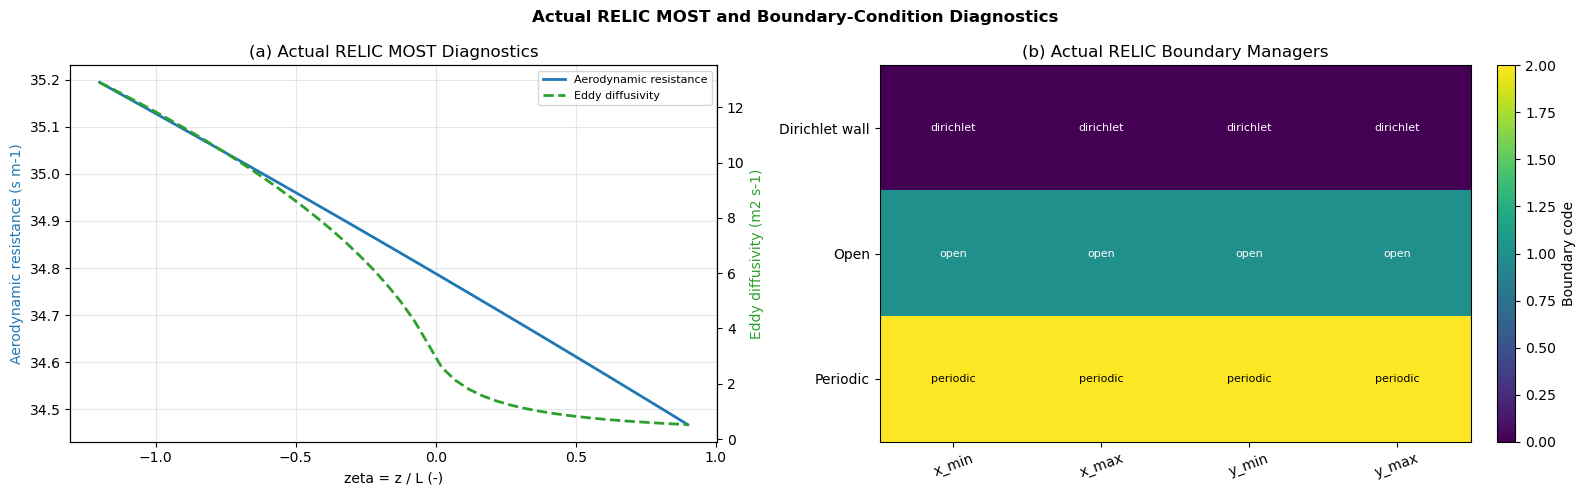

  Aerodynamic resistance range: 34.47 to 35.19 s m-1
  Eddy diffusivity range: 0.52 to 12.90 m2 s-1
  Momentum flux (constant u_star): 0.1470 kg m-1 s-2
  Dirichlet wall: {'x_min': 'dirichlet', 'x_max': 'dirichlet', 'y_min': 'dirichlet', 'y_max': 'dirichlet'}
  Open: {'x_min': 'open', 'x_max': 'open', 'y_min': 'open', 'y_max': 'open'}
  Periodic: {'x_min': 'periodic', 'x_max': 'periodic', 'y_min': 'periodic', 'y_max': 'periodic'}


In [16]:
# Uses actual RELIC MOST utilities and boundary-condition managers rather than notebook-defined transport sketches.
from relic.scientific.atmosphere.most.surface_fluxes import (
    aerodynamic_resistance,
    eddy_diffusivity,
    momentum_flux,
)
from relic.scientific.transport.boundary_conditions import (
    create_dirichlet_walls,
    create_open_boundaries,
    create_periodic_boundaries,
)

# ---------------------------------------------------------------
# References:
#   Monin and Obukhov (1954) -- similarity theory for the surface layer
#   Businger et al. (1971) -- stability corrections used in practical MOST closures
#   LeVeque (2007) -- PDE boundary-condition taxonomy for transport operators
# Mathematical expression:
#   r_a = [ln((z - d) / z0m) - psi_m(zeta) + psi_h(zeta)] / (kappa * u_*)
#   K = kappa * u_* * z * phi_K(zeta)
#   tau = rho * u_*^2
# Parameter meanings:
#   u_star: friction velocity [m s-1]
#   z0m, z0h: momentum and heat roughness lengths [m]
#   zeta: stability coordinate z / L [-]
#   boundary_type: Dirichlet, open, or periodic transport closure on each face
# ---------------------------------------------------------------

import torch
import matplotlib.pyplot as plt
%matplotlib inline

stability_axis = torch.linspace(-1.2, 0.9, 44, dtype=torch.float32)
aerodynamic_resistance_values = []
eddy_diffusivity_values = []
momentum_flux_values = []
for zeta_value in stability_axis:
    u_star = torch.tensor(0.35, dtype=torch.float32)
    measurement_height = torch.tensor(20.0, dtype=torch.float32)
    z0m = torch.tensor(0.15, dtype=torch.float32)
    z0h = torch.tensor(0.02, dtype=torch.float32)
    aerodynamic_resistance_values.append(
        float(aerodynamic_resistance(u_star, measurement_height, z0m, z0h, zeta_value).detach().cpu().item())
    )
    eddy_diffusivity_values.append(
        float(eddy_diffusivity(u_star, measurement_height, zeta_value).detach().cpu().item())
    )
    momentum_flux_values.append(
        float(momentum_flux(u_star, rho=1.2).detach().cpu().item())
    )

boundary_managers = {
    'Dirichlet wall': create_dirichlet_walls(spatial_dims=2, wall_value=0.0),
    'Open': create_open_boundaries(spatial_dims=2),
    'Periodic': create_periodic_boundaries(spatial_dims=2),
}
face_order = ['x_min', 'x_max', 'y_min', 'y_max']
boundary_code_map = {'dirichlet': 0, 'open': 1, 'periodic': 2}
boundary_matrix = []
for manager_name, manager in boundary_managers.items():
    row_codes = []
    for face_name in face_order:
        bc_type = manager.boundary_conditions[face_name].bc_type.value
        row_codes.append(boundary_code_map[bc_type])
    boundary_matrix.append(row_codes)
boundary_matrix_tensor = torch.tensor(boundary_matrix, dtype=torch.float32)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(stability_axis.tolist(), aerodynamic_resistance_values, color='tab:blue', lw=2, label='Aerodynamic resistance')
axes0_twin = axes[0].twinx()
axes0_twin.plot(stability_axis.tolist(), eddy_diffusivity_values, color='tab:green', lw=2, linestyle='--', label='Eddy diffusivity')
axes[0].set_xlabel('zeta = z / L (-)')
axes[0].set_ylabel('Aerodynamic resistance (s m-1)', color='tab:blue')
axes0_twin.set_ylabel('Eddy diffusivity (m2 s-1)', color='tab:green')
axes[0].set_title('(a) Actual RELIC MOST Diagnostics')
axes[0].grid(True, alpha=0.3)
lines_left, labels_left = axes[0].get_legend_handles_labels()
lines_right, labels_right = axes0_twin.get_legend_handles_labels()
axes[0].legend(lines_left + lines_right, labels_left + labels_right, loc='upper right', fontsize=8)

image = axes[1].imshow(boundary_matrix_tensor.tolist(), cmap='viridis', aspect='auto', vmin=0.0, vmax=2.0)
axes[1].set_xticks(range(len(face_order)))
axes[1].set_xticklabels(face_order, rotation=20)
axes[1].set_yticks(range(len(boundary_managers)))
axes[1].set_yticklabels(list(boundary_managers.keys()))
axes[1].set_title('(b) Actual RELIC Boundary Managers')
for row_index, manager_name in enumerate(boundary_managers):
    for col_index, face_name in enumerate(face_order):
        bc_name = boundary_managers[manager_name].boundary_conditions[face_name].bc_type.value
        axes[1].text(col_index, row_index, bc_name, ha='center', va='center', color='black' if image.norm(float(boundary_matrix_tensor[row_index, col_index])) > 0.55 else 'white', fontsize=8)
plt.colorbar(image, ax=axes[1], fraction=0.046, pad=0.04, label='Boundary code')

plt.suptitle('Actual RELIC MOST and Boundary-Condition Diagnostics', fontweight='bold')
plt.tight_layout()
plt.show()

print(f"  Aerodynamic resistance range: {min(aerodynamic_resistance_values):.2f} to {max(aerodynamic_resistance_values):.2f} s m-1")
print(f"  Eddy diffusivity range: {min(eddy_diffusivity_values):.2f} to {max(eddy_diffusivity_values):.2f} m2 s-1")
print(f"  Momentum flux (constant u_star): {momentum_flux_values[0]:.4f} kg m-1 s-2")
for manager_name, manager in boundary_managers.items():
    face_types = {face_name: manager.boundary_conditions[face_name].bc_type.value for face_name in face_order}
    print(f"  {manager_name}: {face_types}")

---
## Multi-Isotope Pools

> **Reference:** `docs/source/theory/multi_isotope_pools.md`

Isotopic composition tracked as delta notation:

$$\delta^{13}C = \left(\frac{R_{\text{sample}}}{R_{\text{standard}}} - 1\right) \times 1000$$

**Fractionation during photosynthesis:**

$$\delta^{13}C_{\text{plant}} = \delta^{13}C_{\text{atm}} - a - (b-a)\frac{c_i}{c_a}$$

where $a \approx 4.4\text{\u2030}$ (diffusion), $b \approx 27\text{\u2030}$ (Rubisco), $c_i/c_a$ = intercellular/ambient CO2.

**Pool mixing** (mass-weighted):

$$\delta_{\text{mix}} = \frac{\sum_i m_i \cdot \delta_i}{\sum_i m_i}$$


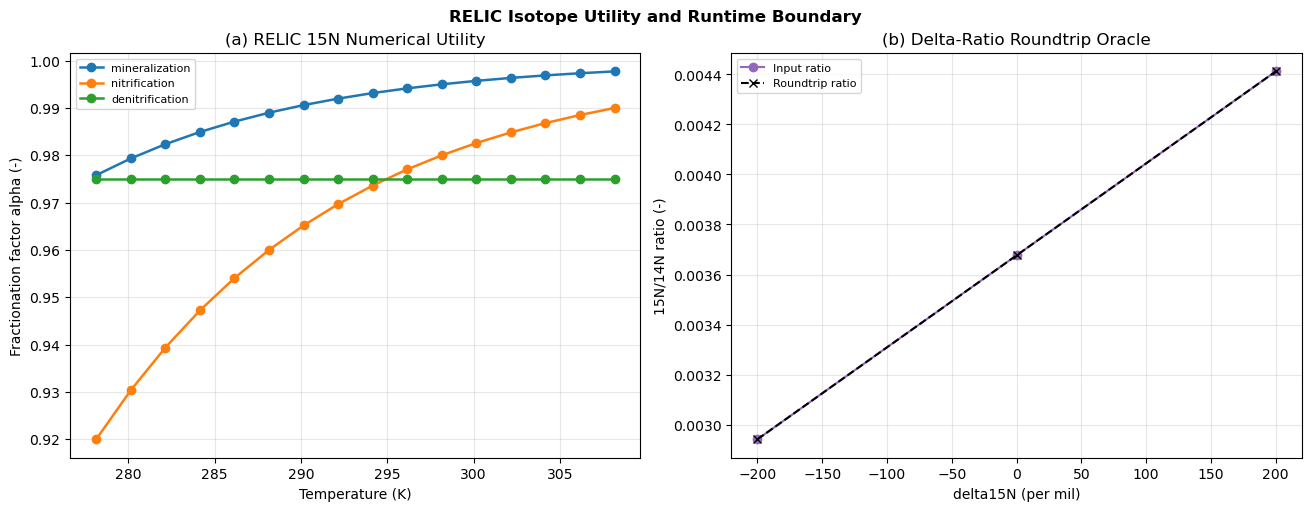

  Supported numerical processes: ['mineralization', 'nitrification', 'denitrification']
  Delta-ratio roundtrip max error: 0.000e+00
  Public runtime status: [N] runtime_unbound
  Runtime blocker: [N] isotope root runtime_unbound


In [17]:
# Uses the current isotope numerical utility and the public fail-closed runtime boundary.
from relic.parameters import get_global_manager
from relic.scientific.isotopes import get_default_config, get_module_info, wire_isotope_tracker
from relic.scientific.isotopes.registry import IsotopeValidationError
from relic.scientific.isotopes.fractionation.nitrogen_15 import Nitrogen15FractionationCalculator

# ---------------------------------------------------------------
# References:
#   Mariotti et al. (1981) -- nitrogen isotope fractionation
#   Robinson (2001) -- delta15N interpretation
# Mathematical expression:
#   delta = (R / R_standard - 1) * 1000
#   R = R_standard * (1 + delta / 1000)
# Parameter meanings:
#   R: 15N/14N isotope ratio [-]
#   alpha_process(T): process fractionation factor [-]
#   T: temperature [K]
# Units: isotope ratios and alpha are dimensionless; delta is per mil.
# Domain/constraints: ratios are positive and temperatures lie in the calculator domain.
# Sign convention: positive delta denotes enrichment relative to the standard ratio.
# ---------------------------------------------------------------

import torch
import matplotlib.pyplot as plt
%matplotlib inline

parameter_manager = get_global_manager()
calculator = Nitrogen15FractionationCalculator(parameter_manager=parameter_manager)
processes = calculator.get_supported_processes()
temperature_points = torch.linspace(278.15, 308.15, 16, dtype=torch.float64)
alpha_records = {
    process: calculator.calculate_fractionation_factor(process, temperature_points).detach().cpu()
    for process in processes
}

natural_ratio = torch.tensor(calculator.get_natural_abundance(), dtype=torch.float64)
ratio_values = natural_ratio * torch.tensor([0.8, 1.0, 1.2], dtype=torch.float64)
delta_values = calculator.delta_notation(ratio_values)
ratio_roundtrip = calculator.ratio_from_delta(delta_values)
torch.testing.assert_close(ratio_roundtrip, ratio_values, rtol=1.0e-12, atol=1.0e-15)

config = get_default_config()
module_info = get_module_info()
assert config.enabled is False
assert module_info['runtime_available'] is False
try:
    wire_isotope_tracker(None, None, config=config)
except IsotopeValidationError as exc:
    runtime_blocker = str(exc)
else:
    raise AssertionError('Stable-isotope runtime must remain fail-closed while the governed ledger is unavailable.')
assert '[N]' in runtime_blocker

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for process, values in alpha_records.items():
    axes[0].plot(temperature_points.tolist(), values.tolist(), marker='o', lw=1.8, label=process)
axes[0].set_xlabel('Temperature (K)')
axes[0].set_ylabel('Fractionation factor alpha (-)')
axes[0].set_title('(a) RELIC 15N Numerical Utility')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].plot(delta_values.tolist(), ratio_values.tolist(), 'o-', color='tab:purple', label='Input ratio')
axes[1].plot(delta_values.tolist(), ratio_roundtrip.tolist(), 'x--', color='black', label='Roundtrip ratio')
axes[1].set_xlabel('delta15N (per mil)')
axes[1].set_ylabel('15N/14N ratio (-)')
axes[1].set_title('(b) Delta-Ratio Roundtrip Oracle')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8)

plt.suptitle('RELIC Isotope Utility and Runtime Boundary', fontweight='bold')
plt.show()

print(f"  Supported numerical processes: {processes}")
print(f"  Delta-ratio roundtrip max error: {float(torch.max(torch.abs(ratio_roundtrip - ratio_values))):.3e}")
print(f"  Public runtime status: {module_info['status']}")
print(f"  Runtime blocker: {runtime_blocker}")

---
## Transport Processes Summary

> **Reference:** `docs/source/theory/transport_*.md`

RELIC implements three canonical transport mechanisms:

1. **Advection** (bulk flow): $\frac{\partial C}{\partial t} + u \frac{\partial C}{\partial x} = 0$

2. **Diffusion** (Fick's law): $F = -D \frac{\partial C}{\partial x}$

3. **Turbulent mixing** (K-theory): $F = -K \frac{\partial C}{\partial z}$

Spatial discretization and numerical guarantees depend on the selected operator and configuration. The diagnostics in this gallery alone do not establish monotonicity or conservation for every transport scheme.


---
## Anthroposphere: Grazing Management

> **Reference:** `docs/source/theory/anthroposphere_management_grazing.md`

Grazing intensity is supplied by the grazing event; the removed `animal_density` state is not a fallback input. Removal and manure-return amounts must be taken from the actual management process and its parameter-backed outputs, not an assumed universal manure fraction.

```python
from relic.scientific.anthroposphere.management import GrazingManagement
```


---
## Anthroposphere: Sector Allocation

> **Reference:** `docs/source/theory/anthroposphere_sector_allocation.md`

Emissions are allocated to economic sectors:

$$E_{\text{sector},i} = \sum_j \alpha_{ij} \cdot A_j \cdot EF_j$$

where $\alpha_{ij}$ = allocation fraction, $A_j$ = activity level,
$EF_j$ = emission factor.

**Sectors in RELIC:**

| Sector | Examples | Key emissions |
|--------|----------|:-------------:|
| Energy | Power plants, boilers | CO2, SOx, NOx |
| Industry | Manufacturing, cement | CO2, PM |
| Transport | Vehicles, shipping | CO, NOx, VOC |
| Agriculture | Livestock, rice paddies | CH4, N2O, NH3 |
| Residential | Cooking, heating | CO, PM2.5 |
| Waste | Landfills, wastewater | CH4, N2O |

**In RELIC:**
```python
from relic.scientific.anthroposphere.emissions.sector_allocation import SectorAllocation
```


## Summary: Domain Coverage

This gallery constructs `RadiationField`, `FarquharPhotosynthesis`, `BucketSoilMoisture`, `FirstOrderDecomposition`, and `ManagementCoordinator`, and probes selected nutrient, methane, deposition, and transport kernels. Isotope numerical utilities are demonstrated separately from the unavailable public isotope runtime. A class import or direct kernel call does not verify simulator registration, dependency closure, state commits, or a whole-run conservation claim.

**Next**: NB19 for post-processing and evaluation, NB20 for calibration.
